<a href="https://colab.research.google.com/github/oabdelhalim8/ML---10/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

In [3]:
if IS_COLAB:
    %pip install -q torchmetrics

In [4]:
from packaging.version import Version
import torch

assert Version(torch.__version__) >= Version("2.6.0")

In [5]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

In [6]:
if device == "cpu":
    print("Neural nets can be very slow without a hardware accelerator.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")

Neural nets can be very slow without a hardware accelerator.
Go to Runtime > Change runtime and select a GPU hardware accelerator.


In [7]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

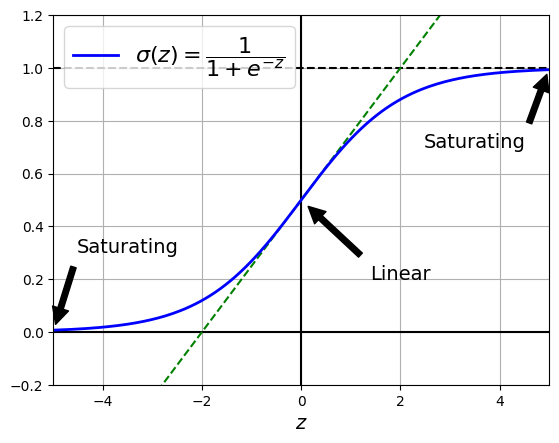

In [8]:
# extra code – this cell generates Figure 11–1

import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-5, 5, 200)

plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [1, 1], 'k--')
plt.plot([0, 0], [-0.2, 1.2], 'k-')
plt.plot([-5, 5], [-3/4, 7/4], 'g--')
plt.plot(z, sigmoid(z), "b-", linewidth=2,
         label=r"$\sigma(z) = \dfrac{1}{1+e^{-z}}$")
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Saturating', xytext=(3.5, 0.7), xy=(5, 1), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Saturating', xytext=(-3.5, 0.3), xy=(-5, 0), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Linear', xytext=(2, 0.2), xy=(0, 0.5), arrowprops=props,
             fontsize=14, ha="center")
plt.grid(True)
plt.axis([-5, 5, -0.2, 1.2])
plt.xlabel("$z$")
plt.legend(loc="upper left", fontsize=16)

plt.show()

In [9]:
import torch
import torch.nn as nn

layer = nn.Linear(40, 10)
layer.weight.data *= 6 ** 0.5  # Kaiming init (or 3 ** 0.5 for LeCun init)
torch.zero_(layer.bias.data)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [10]:
layer = nn.Linear(40, 10)
nn.init.kaiming_uniform_(layer.weight)
nn.init.zeros_(layer.bias)

Parameter containing:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

In [11]:
def use_he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

model = nn.Sequential(nn.Linear(50, 40), nn.ReLU(), nn.Linear(40, 1), nn.ReLU())
model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): ReLU()
  (2): Linear(in_features=40, out_features=1, bias=True)
  (3): ReLU()
)

In [12]:
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=0.2))
model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
)

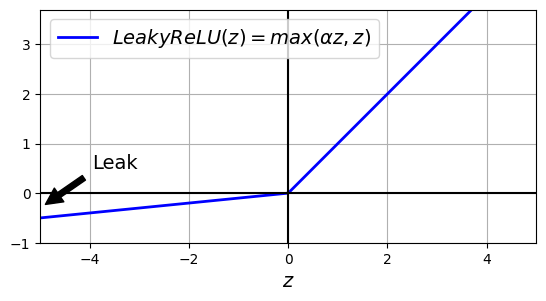

In [13]:
# extra code – this cell generates Figure 11–2

def leaky_relu(z, alpha):
    return np.maximum(alpha * z, z)

z = np.linspace(-5, 5, 200)
plt.plot(z, leaky_relu(z, 0.1), "b-", linewidth=2, label=r"$LeakyReLU(z) = max(\alpha z, z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-1, 3.7], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.3), arrowprops=props,
             fontsize=14, ha="center")
plt.xlabel("$z$")
plt.axis([-5, 5, -1, 3.7])
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [14]:
torch.manual_seed(42)
alpha = 0.2
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=alpha))
nn.init.kaiming_uniform_(model[0].weight, alpha, nonlinearity="leaky_relu")
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [15]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.ELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

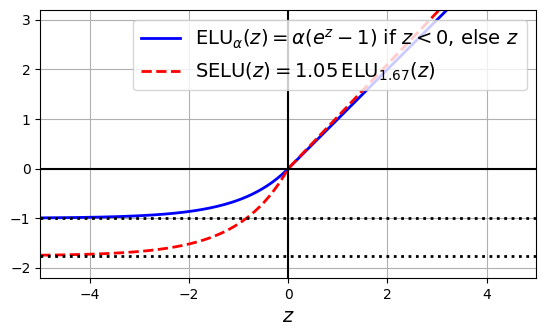

In [16]:
# extra code – this cell generates Figure 11–3

from scipy.special import erfc

# alpha and scale to self normalize with mean 0 and standard deviation 1
# (see equation 14 in the paper):
alpha_0_1 = -np.sqrt(2 / np.pi) / (erfc(1 / np.sqrt(2)) * np.exp(1 / 2) - 1)
scale_0_1 = (
    (1 - erfc(1 / np.sqrt(2)) * np.sqrt(np.e))
    * np.sqrt(2 * np.pi)
    * (
        2 * erfc(np.sqrt(2)) * np.e ** 2
        + np.pi * erfc(1 / np.sqrt(2)) ** 2 * np.e
        - 2 * (2 + np.pi) * erfc(1 / np.sqrt(2)) * np.sqrt(np.e)
        + np.pi
        + 2
    ) ** (-1 / 2)
)

def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

def selu(z, scale=scale_0_1, alpha=alpha_0_1):
    return scale * elu(z, alpha)

z = np.linspace(-5, 5, 200)
plt.plot(z, elu(z), "b-", linewidth=2, label=r"ELU$_\alpha(z) = \alpha (e^z - 1)$ if $z < 0$, else $z$")
plt.plot(z, selu(z), "r--", linewidth=2, label=r"SELU$(z) = 1.05 \, $ELU$_{1.67}(z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k:', linewidth=2)
plt.plot([-5, 5], [-1.758, -1.758], 'k:', linewidth=2)
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-5, 5, -2.2, 3.2])
plt.xlabel("$z$")
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [17]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.SELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

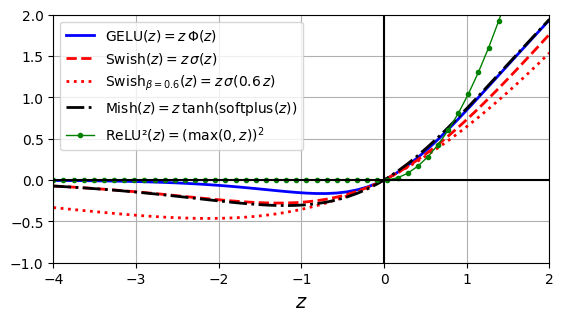

In [18]:
# extra code – this cell generates Figure 11–4

def swish(z, beta=1):
    return z * sigmoid(beta * z)

def approx_gelu(z):
    return swish(z, beta=1.702)

def softplus(z):
    return np.log(1 + np.exp(z))

def mish(z):
    return z * np.tanh(softplus(z))

def relu_squared(z):
    return np.maximum(0, z)**2

z = np.linspace(-4, 2, 50)

beta = 0.6
plt.plot(z, approx_gelu(z), "b-", linewidth=2,
         label=r"GELU$(z) = z\,\Phi(z)$")
plt.plot(z, swish(z), "r--", linewidth=2,
         label=r"Swish$(z) = z\,\sigma(z)$")
plt.plot(z, swish(z, beta), "r:", linewidth=2,
         label=fr"Swish$_{{\beta={beta}}}(z)=z\,\sigma({beta}\,z)$")
plt.plot(z, mish(z), "k-.", linewidth=2,
         label=fr"Mish$(z) = z\,\tanh($softplus$(z))$")
plt.plot(z, relu_squared(z), "g.-", linewidth=1,
         label=fr"ReLU²$(z) = (\max(0, z))^2$")
plt.plot([-4, 2], [0, 0], 'k-')
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-4, 2, -1, 2])
plt.gca().set_aspect("equal")
plt.xlabel("$z$")
#plt.legend(loc="upper left")
plt.legend(loc="upper left", fontsize=10)

plt.show()

In [19]:
class SwiGLU(nn.Module):
    def __init__(self, beta=1.0):
        super().__init__()
        self.beta = beta

    def forward(self, x):
        z1, z2 = x.chunk(2, dim=-1)
        param_swish = z1 * torch.sigmoid(self.beta * z1)
        return param_swish * z2

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 2 * 40), SwiGLU(beta=0.2))
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [20]:
import torch.nn.functional as F

class ReLU2(nn.Module):
    def forward(self, x):
        return F.relu(x).square()

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), ReLU2())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [21]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Flatten(),
    nn.BatchNorm1d(1 * 28 * 28),
    nn.Linear(1 * 28 * 28, 300),
    nn.ReLU(),
    nn.BatchNorm1d(300),
    nn.Linear(300, 100),
    nn.ReLU(),
    nn.BatchNorm1d(100),
    nn.Linear(100, 10)
)

In [22]:
dict(model[1].named_parameters()).keys()

dict_keys(['weight', 'bias'])

In [23]:
dict(model[1].named_buffers()).keys()

dict_keys(['running_mean', 'running_var', 'num_batches_tracked'])

In [24]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 300, bias=False),
    nn.BatchNorm1d(300),
    nn.ReLU(),
    nn.Linear(300, 100, bias=False),
    nn.BatchNorm1d(100),
    nn.ReLU(),
    nn.Linear(100, 10)
)

In [25]:
torch.manual_seed(42)

inputs = torch.randn(32, 3, 100, 200)  # a batch of random RGB images
layer_norm = nn.LayerNorm([100, 200])
result = layer_norm(inputs)  # normalizes over the last two dimensions

In [26]:
means = inputs.mean(dim=[2, 3], keepdim=True)
vars_ = inputs.var(dim=[2, 3], keepdim=True, unbiased=False)
stds = torch.sqrt(vars_ + layer_norm.eps)
result2 = layer_norm.weight * (inputs - means) / stds + layer_norm.bias
assert torch.allclose(result, result2)

In [27]:
layer_norm = nn.LayerNorm([3, 100, 200])
result = layer_norm(inputs)  # normalizes over the last three dimensions

In [28]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import fetch_openml

fashion_mnist = fetch_openml(name="Fashion-MNIST", as_frame=False)
X = torch.FloatTensor(fashion_mnist.data.reshape(-1, 1, 28, 28) / 255.)
y = torch.from_numpy(fashion_mnist.target.astype(int))
in_B = (y == 0) | (y == 2)  # Pullover or T-shirt/top
X_A, y_A = X[~in_B], y[~in_B]
y_A = torch.maximum(y_A - 2, torch.tensor(0))  # [1,3,4,5,6,7,8,9] => [0,..,7]
X_B, y_B = X[in_B], (y[in_B] == 2).to(dtype=torch.float32).view(-1, 1)

train_set_A = TensorDataset(X_A[:-7_000], y_A[:-7000])
valid_set_A = TensorDataset(X_A[-7_000:-5000], y_A[-7000:-5000])
test_set_A = TensorDataset(X_A[-5_000:], y_A[-5000:])
train_set_B = TensorDataset(X_B[:20], y_B[:20])
valid_set_B = TensorDataset(X_B[20:5000], y_B[20:5000])
test_set_B = TensorDataset(X_B[5_000:], y_B[5000:])

train_loader_A = DataLoader(train_set_A, batch_size=32, shuffle=True)
valid_loader_A = DataLoader(valid_set_A, batch_size=32)
test_loader_A = DataLoader(test_set_A, batch_size=32)
train_loader_B = DataLoader(train_set_B, batch_size=32, shuffle=True)
valid_loader_B = DataLoader(valid_set_B, batch_size=32)
test_loader_B = DataLoader(test_set_B, batch_size=32)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:75: RuntimeWarning: Invalid cache, redownloading file
  warn("Invalid cache, redownloading file", RuntimeWarning)


In [29]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            # Uncomment to activate gradient clipping:
            #nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [30]:
torch.manual_seed(42)

model_A = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 8)
)
model_A = model_A.to(device)

In [31]:
model_A.apply(use_he_init)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Linear(in_features=100, out_features=8, bias=True)
)

In [32]:
n_epochs = 20
optimizer = torch.optim.SGD(model_A.parameters(), lr=0.005)
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
history_A = train(model_A, optimizer, xentropy, accuracy,
                  train_loader_A, valid_loader_A, n_epochs)

Epoch 1/20, train loss: 0.5995, train metric: 0.7997, valid metric: 0.8695
Epoch 2/20, train loss: 0.3416, train metric: 0.8807, valid metric: 0.8920
Epoch 3/20, train loss: 0.2961, train metric: 0.8970, valid metric: 0.8940
Epoch 4/20, train loss: 0.2715, train metric: 0.9065, valid metric: 0.9030
Epoch 5/20, train loss: 0.2571, train metric: 0.9106, valid metric: 0.8965
Epoch 6/20, train loss: 0.2430, train metric: 0.9155, valid metric: 0.9040
Epoch 7/20, train loss: 0.2328, train metric: 0.9192, valid metric: 0.9030
Epoch 8/20, train loss: 0.2243, train metric: 0.9234, valid metric: 0.9070
Epoch 9/20, train loss: 0.2164, train metric: 0.9242, valid metric: 0.9080
Epoch 10/20, train loss: 0.2097, train metric: 0.9270, valid metric: 0.9100
Epoch 11/20, train loss: 0.2043, train metric: 0.9285, valid metric: 0.9085
Epoch 12/20, train loss: 0.1979, train metric: 0.9305, valid metric: 0.9130
Epoch 13/20, train loss: 0.1923, train metric: 0.9319, valid metric: 0.9075
Epoch 14/20, train lo

In [33]:
torch.manual_seed(9)

model_B = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 1)
).to(device)

In [34]:
model_B.apply(use_he_init)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Linear(in_features=100, out_features=1, bias=True)
)

In [35]:
n_epochs = 20
optimizer = torch.optim.SGD(model_B.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/20, train loss: 0.7413, train metric: 0.6000, valid metric: 0.4639
Epoch 2/20, train loss: 0.7117, train metric: 0.6000, valid metric: 0.4833
Epoch 3/20, train loss: 0.6846, train metric: 0.6500, valid metric: 0.5191
Epoch 4/20, train loss: 0.6608, train metric: 0.6500, valid metric: 0.5592
Epoch 5/20, train loss: 0.6391, train metric: 0.6500, valid metric: 0.6032
Epoch 6/20, train loss: 0.6186, train metric: 0.7500, valid metric: 0.6402
Epoch 7/20, train loss: 0.5986, train metric: 0.8000, valid metric: 0.6805
Epoch 8/20, train loss: 0.5795, train metric: 0.8500, valid metric: 0.7135
Epoch 9/20, train loss: 0.5621, train metric: 0.8500, valid metric: 0.7382
Epoch 10/20, train loss: 0.5457, train metric: 0.9000, valid metric: 0.7627
Epoch 11/20, train loss: 0.5303, train metric: 0.9000, valid metric: 0.7797
Epoch 12/20, train loss: 0.5158, train metric: 0.9000, valid metric: 0.7956
Epoch 13/20, train loss: 0.5024, train metric: 0.9000, valid metric: 0.8092
Epoch 14/20, train lo

In [36]:
evaluate_tm(model_B, test_loader_B, accuracy)

tensor(0.8652)

In [37]:
import copy

torch.manual_seed(43)
reused_layers = copy.deepcopy(model_A[:-1])
model_B_on_A = nn.Sequential(
    *reused_layers,
    nn.Linear(100, 1)  # new output layer for task B
).to(device)

In [38]:
for layer in model_B_on_A[:-1]:
    for param in layer.parameters():
        param.requires_grad = False

In [39]:
n_epochs = 10
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/10, train loss: 0.7859, train metric: 0.1500, valid metric: 0.3910
Epoch 2/10, train loss: 0.7604, train metric: 0.2500, valid metric: 0.4241
Epoch 3/10, train loss: 0.7371, train metric: 0.4000, valid metric: 0.4490
Epoch 4/10, train loss: 0.7155, train metric: 0.4500, valid metric: 0.4769
Epoch 5/10, train loss: 0.6950, train metric: 0.5000, valid metric: 0.5026
Epoch 6/10, train loss: 0.6756, train metric: 0.5500, valid metric: 0.5309
Epoch 7/10, train loss: 0.6572, train metric: 0.7000, valid metric: 0.5649
Epoch 8/10, train loss: 0.6398, train metric: 0.7000, valid metric: 0.5984
Epoch 9/10, train loss: 0.6232, train metric: 0.7000, valid metric: 0.6343
Epoch 10/10, train loss: 0.6075, train metric: 0.7000, valid metric: 0.6725


In [40]:
for layer in model_B_on_A[2:]:
    for param in layer.parameters():
        param.requires_grad = True

In [41]:
n_epochs = 20
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/20, train loss: 0.5925, train metric: 0.7500, valid metric: 0.7127
Epoch 2/20, train loss: 0.5750, train metric: 0.7500, valid metric: 0.7480
Epoch 3/20, train loss: 0.5585, train metric: 0.8500, valid metric: 0.7781
Epoch 4/20, train loss: 0.5429, train metric: 0.8500, valid metric: 0.8042
Epoch 5/20, train loss: 0.5281, train metric: 0.8500, valid metric: 0.8229
Epoch 6/20, train loss: 0.5141, train metric: 0.8500, valid metric: 0.8386
Epoch 7/20, train loss: 0.5008, train metric: 0.9000, valid metric: 0.8514
Epoch 8/20, train loss: 0.4881, train metric: 0.9000, valid metric: 0.8608
Epoch 9/20, train loss: 0.4761, train metric: 0.9000, valid metric: 0.8703
Epoch 10/20, train loss: 0.4646, train metric: 0.9000, valid metric: 0.8761
Epoch 11/20, train loss: 0.4537, train metric: 0.9500, valid metric: 0.8825
Epoch 12/20, train loss: 0.4433, train metric: 0.9500, valid metric: 0.8896
Epoch 13/20, train loss: 0.4334, train metric: 0.9500, valid metric: 0.8922
Epoch 14/20, train lo

In [42]:
evaluate_tm(model_B_on_A, test_loader_B, accuracy)

tensor(0.9134)

In [43]:
# extra code – a little function to test an optimizer on Fashion MNIST

train_set = TensorDataset(X[:55_000], y[:55_000])
valid_set = TensorDataset(X[55_000:60_000], y[55_000:60_000])
test_set = TensorDataset(X[60_000:], y[60_000:])

def build_model(seed=42):
    torch.manual_seed(seed)
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 10)
    ).to(device)
    model.apply(use_he_init)
    return model

def test_optimizer(model, optimizer, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10)
    history = train(model, optimizer, xentropy, accuracy.to(device),
                    train_loader, valid_loader, n_epochs)
    return history, evaluate_tm(model, test_loader, accuracy)

In [44]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
history_sgd, acc_sgd = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Epoch 2/10, train loss: 0.4009, train metric: 0.8529, valid metric: 0.8340
Epoch 3/10, train loss: 0.3620, train metric: 0.8661, valid metric: 0.8718
Epoch 4/10, train loss: 0.3369, train metric: 0.8743, valid metric: 0.8742
Epoch 5/10, train loss: 0.3184, train metric: 0.8815, valid metric: 0.8562
Epoch 6/10, train loss: 0.3013, train metric: 0.8886, valid metric: 0.8816
Epoch 7/10, train loss: 0.2906, train metric: 0.8921, valid metric: 0.8716
Epoch 8/10, train loss: 0.2790, train metric: 0.8956, valid metric: 0.8858
Epoch 9/10, train loss: 0.2701, train metric: 0.8986, valid metric: 0.8664
Epoch 10/10, train loss: 0.2611, train metric: 0.9020, valid metric: 0.8742


In [45]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), momentum=0.9, lr=0.05)
history_momentum, acc_momentum = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.6205, train metric: 0.7750, valid metric: 0.8292
Epoch 2/10, train loss: 0.4802, train metric: 0.8280, valid metric: 0.8430
Epoch 3/10, train loss: 0.4413, train metric: 0.8431, valid metric: 0.8378
Epoch 4/10, train loss: 0.4249, train metric: 0.8489, valid metric: 0.8428
Epoch 5/10, train loss: 0.4137, train metric: 0.8531, valid metric: 0.8614
Epoch 6/10, train loss: 0.4011, train metric: 0.8577, valid metric: 0.8496
Epoch 7/10, train loss: 0.3853, train metric: 0.8630, valid metric: 0.8638
Epoch 8/10, train loss: 0.3833, train metric: 0.8625, valid metric: 0.8518
Epoch 9/10, train loss: 0.3760, train metric: 0.8668, valid metric: 0.8432
Epoch 10/10, train loss: 0.3787, train metric: 0.8657, valid metric: 0.8490


In [46]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(),
                            momentum=0.9, nesterov=True, lr=0.05)
history_nesterov, acc_nesterov = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5645, train metric: 0.7937, valid metric: 0.8216
Epoch 2/10, train loss: 0.4428, train metric: 0.8409, valid metric: 0.8470
Epoch 3/10, train loss: 0.4115, train metric: 0.8518, valid metric: 0.8476
Epoch 4/10, train loss: 0.3986, train metric: 0.8571, valid metric: 0.8510
Epoch 5/10, train loss: 0.3851, train metric: 0.8635, valid metric: 0.8490
Epoch 6/10, train loss: 0.3684, train metric: 0.8694, valid metric: 0.8600
Epoch 7/10, train loss: 0.3610, train metric: 0.8710, valid metric: 0.8634
Epoch 8/10, train loss: 0.3524, train metric: 0.8745, valid metric: 0.8644
Epoch 9/10, train loss: 0.3492, train metric: 0.8758, valid metric: 0.8556
Epoch 10/10, train loss: 0.3404, train metric: 0.8773, valid metric: 0.8580


In [47]:
model = build_model()  # extra code
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.05)
history_adagrad, acc_adagrad = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5657, train metric: 0.8089, valid metric: 0.8396
Epoch 2/10, train loss: 0.3703, train metric: 0.8639, valid metric: 0.8460
Epoch 3/10, train loss: 0.3357, train metric: 0.8761, valid metric: 0.8726
Epoch 4/10, train loss: 0.3149, train metric: 0.8837, valid metric: 0.8740
Epoch 5/10, train loss: 0.2996, train metric: 0.8893, valid metric: 0.8752
Epoch 6/10, train loss: 0.2852, train metric: 0.8945, valid metric: 0.8762
Epoch 7/10, train loss: 0.2761, train metric: 0.8975, valid metric: 0.8822
Epoch 8/10, train loss: 0.2666, train metric: 0.8999, valid metric: 0.8832
Epoch 9/10, train loss: 0.2584, train metric: 0.9034, valid metric: 0.8690
Epoch 10/10, train loss: 0.2514, train metric: 0.9065, valid metric: 0.8768


In [48]:
model = build_model()  # extra code
optimizer = torch.optim.RMSprop(model.parameters(), alpha=0.9, lr=0.05)
history_rmsprop, acc_rmsprop = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 2.6893, train metric: 0.4509, valid metric: 0.4378
Epoch 2/10, train loss: 1.4809, train metric: 0.4389, valid metric: 0.4064
Epoch 3/10, train loss: 1.4620, train metric: 0.4479, valid metric: 0.5188
Epoch 4/10, train loss: 1.4779, train metric: 0.4543, valid metric: 0.4380
Epoch 5/10, train loss: 1.3997, train metric: 0.4440, valid metric: 0.2884
Epoch 6/10, train loss: 1.5003, train metric: 0.4242, valid metric: 0.4456
Epoch 7/10, train loss: 1.5026, train metric: 0.4280, valid metric: 0.3734
Epoch 8/10, train loss: 1.4916, train metric: 0.4219, valid metric: 0.4474
Epoch 9/10, train loss: 1.4471, train metric: 0.4213, valid metric: 0.4090
Epoch 10/10, train loss: 1.4840, train metric: 0.4127, valid metric: 0.4110


In [49]:
model = build_model()  # extra code
optimizer = torch.optim.Adam(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_adam, acc_adam = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 1.1870, train metric: 0.5547, valid metric: 0.4884
Epoch 2/10, train loss: 1.3970, train metric: 0.4113, valid metric: 0.4474
Epoch 3/10, train loss: 1.2323, train metric: 0.4735, valid metric: 0.4712
Epoch 4/10, train loss: 1.3806, train metric: 0.4306, valid metric: 0.4438
Epoch 5/10, train loss: 1.3522, train metric: 0.4324, valid metric: 0.4240
Epoch 6/10, train loss: 1.1814, train metric: 0.4967, valid metric: 0.4812
Epoch 7/10, train loss: 1.2457, train metric: 0.4738, valid metric: 0.4602
Epoch 8/10, train loss: 1.3018, train metric: 0.4305, valid metric: 0.4058
Epoch 9/10, train loss: 1.3203, train metric: 0.4090, valid metric: 0.4204
Epoch 10/10, train loss: 1.3297, train metric: 0.4069, valid metric: 0.4294


In [50]:
model = build_model()  # extra code
optimizer = torch.optim.Adamax(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_adamax, acc_adamax = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.6380, train metric: 0.7830, valid metric: 0.8120
Epoch 2/10, train loss: 0.4743, train metric: 0.8304, valid metric: 0.8384
Epoch 3/10, train loss: 0.4412, train metric: 0.8430, valid metric: 0.8376
Epoch 4/10, train loss: 0.4194, train metric: 0.8491, valid metric: 0.8608
Epoch 5/10, train loss: 0.4060, train metric: 0.8560, valid metric: 0.8596
Epoch 6/10, train loss: 0.3921, train metric: 0.8604, valid metric: 0.8490
Epoch 7/10, train loss: 0.3811, train metric: 0.8660, valid metric: 0.8612
Epoch 8/10, train loss: 0.3774, train metric: 0.8667, valid metric: 0.8538
Epoch 9/10, train loss: 0.3734, train metric: 0.8674, valid metric: 0.8532
Epoch 10/10, train loss: 0.3624, train metric: 0.8716, valid metric: 0.8444


In [51]:
model = build_model()  # extra code
optimizer = torch.optim.NAdam(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_nadam, acc_nadam = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 1.3337, train metric: 0.4827, valid metric: 0.1944
Epoch 2/10, train loss: 1.8954, train metric: 0.1871, valid metric: 0.1986
Epoch 3/10, train loss: 1.7566, train metric: 0.1936, valid metric: 0.1942
Epoch 4/10, train loss: 1.7300, train metric: 0.1965, valid metric: 0.1926
Epoch 5/10, train loss: 1.7585, train metric: 0.1973, valid metric: 0.1938
Epoch 6/10, train loss: 1.7147, train metric: 0.1973, valid metric: 0.1952
Epoch 7/10, train loss: 1.7149, train metric: 0.1995, valid metric: 0.1906
Epoch 8/10, train loss: 1.7240, train metric: 0.1973, valid metric: 0.2060
Epoch 9/10, train loss: 1.7486, train metric: 0.1975, valid metric: 0.1914
Epoch 10/10, train loss: 1.7389, train metric: 0.1960, valid metric: 0.1990


In [52]:
model = build_model()  # extra code
optimizer = torch.optim.AdamW(model.parameters(), betas=(0.9, 0.999),
                              weight_decay=1e-5, lr=0.05)
history_adamw, acc_adamw = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 1.1376, train metric: 0.5890, valid metric: 0.4626
Epoch 2/10, train loss: 1.3734, train metric: 0.4267, valid metric: 0.4476
Epoch 3/10, train loss: 1.3555, train metric: 0.4299, valid metric: 0.4102
Epoch 4/10, train loss: 1.3595, train metric: 0.4097, valid metric: 0.4834
Epoch 5/10, train loss: 1.2418, train metric: 0.4760, valid metric: 0.4596
Epoch 6/10, train loss: 1.2898, train metric: 0.4418, valid metric: 0.4382
Epoch 7/10, train loss: 1.3163, train metric: 0.4306, valid metric: 0.4492
Epoch 8/10, train loss: 1.3161, train metric: 0.4293, valid metric: 0.4468
Epoch 9/10, train loss: 1.3914, train metric: 0.4017, valid metric: 0.4286
Epoch 10/10, train loss: 1.3769, train metric: 0.4160, valid metric: 0.4168


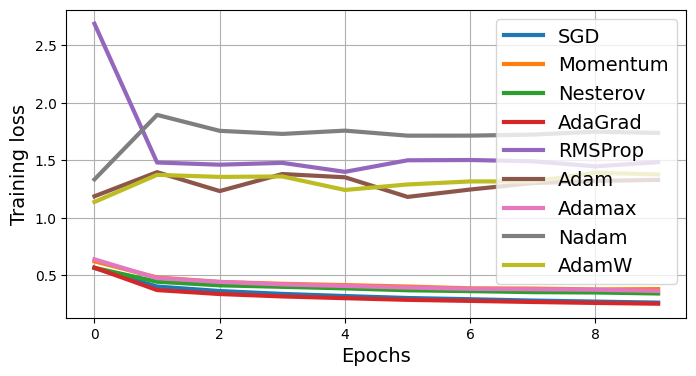

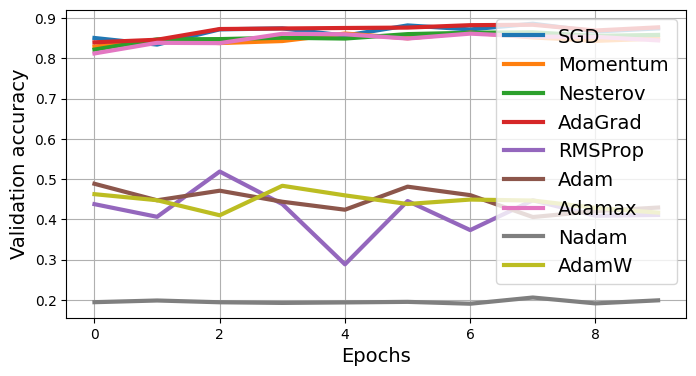

In [53]:
# extra code – visualize the learning curves of all the optimizers

for plot in ("train_losses", "valid_metrics"):
    plt.figure(figsize=(8, 4))
    opt_names = "SGD Momentum Nesterov AdaGrad RMSProp Adam Adamax Nadam AdamW"
    for history, opt_name in zip(
        (history_sgd, history_momentum, history_nesterov, history_adagrad,
         history_rmsprop, history_adam, history_adamax, history_nadam,
         history_adamw), opt_names.split()):
        plt.plot(history[plot], label=opt_name, linewidth=3)

    plt.grid()
    plt.xlabel("Epochs")
    plt.ylabel({"train_losses": "Training loss", "valid_metrics": "Validation accuracy"}[plot])
    plt.legend(loc="upper right")
    plt.show()

In [54]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
exp_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

In [55]:
def train_with_scheduler(model, optimizer, loss_fn, metric, train_loader,
                         valid_loader, n_epochs, scheduler):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        losses = []
        metric.reset()
        for X_batch, y_batch in train_loader:
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            losses.append(loss.item())
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(np.mean(losses))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_metric)
        else:
            scheduler.step()
        print(f"Learning rate: {scheduler.get_last_lr()[0]:.5f}")
    return history

def test_scheduler(model, optimizer, scheduler, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
    history = train_with_scheduler(
        model, optimizer, xentropy, metric, train_loader, valid_loader,
        n_epochs, scheduler)
    return history, evaluate_tm(model, test_loader, metric)

In [56]:
history_exp, acc_exp = test_scheduler(model, optimizer, exp_scheduler)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Learning rate: 0.04500
Epoch 2/10, train loss: 0.3972, train metric: 0.8550, valid metric: 0.8286
Learning rate: 0.04050
Epoch 3/10, train loss: 0.3547, train metric: 0.8682, valid metric: 0.8724
Learning rate: 0.03645
Epoch 4/10, train loss: 0.3289, train metric: 0.8782, valid metric: 0.8682
Learning rate: 0.03281
Epoch 5/10, train loss: 0.3092, train metric: 0.8855, valid metric: 0.8712
Learning rate: 0.02952
Epoch 6/10, train loss: 0.2914, train metric: 0.8922, valid metric: 0.8796
Learning rate: 0.02657
Epoch 7/10, train loss: 0.2787, train metric: 0.8966, valid metric: 0.8792
Learning rate: 0.02391
Epoch 8/10, train loss: 0.2671, train metric: 0.9011, valid metric: 0.8850
Learning rate: 0.02152
Epoch 9/10, train loss: 0.2573, train metric: 0.9057, valid metric: 0.8670
Learning rate: 0.01937
Epoch 10/10, train loss: 0.2482, train metric: 0.9074, valid metric: 0.8818
Learning rate: 0.01743


In [57]:
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=0.001)

In [58]:
history_cos, acc_cos = test_scheduler(model, optimizer, cosine_scheduler)  # extra code

Epoch 1/10, train loss: 0.2402, train metric: 0.9109, valid metric: 0.8838
Learning rate: 0.01733
Epoch 2/10, train loss: 0.2338, train metric: 0.9126, valid metric: 0.8768
Learning rate: 0.01703
Epoch 3/10, train loss: 0.2294, train metric: 0.9137, valid metric: 0.8828
Learning rate: 0.01654
Epoch 4/10, train loss: 0.2242, train metric: 0.9175, valid metric: 0.8854
Learning rate: 0.01586
Epoch 5/10, train loss: 0.2194, train metric: 0.9186, valid metric: 0.8880
Learning rate: 0.01503
Epoch 6/10, train loss: 0.2130, train metric: 0.9205, valid metric: 0.8876
Learning rate: 0.01405
Epoch 7/10, train loss: 0.2080, train metric: 0.9227, valid metric: 0.8862
Learning rate: 0.01295
Epoch 8/10, train loss: 0.2026, train metric: 0.9249, valid metric: 0.8910
Learning rate: 0.01176
Epoch 9/10, train loss: 0.1970, train metric: 0.9265, valid metric: 0.8886
Learning rate: 0.01050
Epoch 10/10, train loss: 0.1915, train metric: 0.9288, valid metric: 0.8860
Learning rate: 0.00922


In [59]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
perf_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=2, factor=0.1)

In [60]:
history_perf, acc_perf = test_scheduler(model, optimizer, perf_scheduler)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Learning rate: 0.05000
Epoch 2/10, train loss: 0.4009, train metric: 0.8529, valid metric: 0.8340
Learning rate: 0.05000
Epoch 3/10, train loss: 0.3620, train metric: 0.8661, valid metric: 0.8718
Learning rate: 0.05000
Epoch 4/10, train loss: 0.3369, train metric: 0.8743, valid metric: 0.8742
Learning rate: 0.05000
Epoch 5/10, train loss: 0.3184, train metric: 0.8815, valid metric: 0.8562
Learning rate: 0.05000
Epoch 6/10, train loss: 0.3013, train metric: 0.8886, valid metric: 0.8816
Learning rate: 0.05000
Epoch 7/10, train loss: 0.2906, train metric: 0.8921, valid metric: 0.8716
Learning rate: 0.05000
Epoch 8/10, train loss: 0.2790, train metric: 0.8956, valid metric: 0.8858
Learning rate: 0.05000
Epoch 9/10, train loss: 0.2701, train metric: 0.8986, valid metric: 0.8664
Learning rate: 0.05000
Epoch 10/10, train loss: 0.2611, train metric: 0.9020, valid metric: 0.8742
Learning rate: 0.05000


In [61]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)

In [62]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
warmup_scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda epoch: (min(epoch, 3) / 3) * (1.0 - 0.1) + 0.1)

In [63]:
# extra code
def train_with_warmup(model, optimizer, loss_fn, metric, train_loader,
                      valid_loader, n_epochs, warmup_scheduler, scheduler):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):

        #warmup_scheduler.step()

        # extra code
        losses = []
        metric.reset()

        for X_batch, y_batch in train_loader:

            # extra code
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            losses.append(loss.item())
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(np.mean(losses))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")

        #if epoch >= 3:  # deactivate other scheduler(s) during warmup
            #scheduler.step(val_metric)
        # Called after the training batches and validation
        if epoch < 3:
          warmup_scheduler.step()
        else:
          scheduler.step(val_metric)


        # extra code
        #print(f"Learning rate: {scheduler.get_last_lr()[0]:.5f}")
        print(f'Learning rate: {optimizer.param_groups[0]["lr"]:.5f}')
    return history


def test_warmup_scheduler(model, optimizer, warmup_scheduler, scheduler,
                          n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
    history = train_with_warmup(
        model, optimizer, xentropy, metric, train_loader, valid_loader,
        n_epochs, warmup_scheduler, scheduler)
    return history, evaluate_tm(model, test_loader, metric)

In [64]:
perf_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=1, factor=0.1)
test_warmup_scheduler(model, optimizer, warmup_scheduler, perf_scheduler,
                      n_epochs=10, batch_size=32)

Epoch 1/10, train loss: 0.8007, train metric: 0.7308, valid metric: 0.8176
Learning rate: 0.02000
Epoch 2/10, train loss: 0.5131, train metric: 0.8203, valid metric: 0.8090
Learning rate: 0.03500
Epoch 3/10, train loss: 0.4352, train metric: 0.8411, valid metric: 0.8578
Learning rate: 0.05000
Epoch 4/10, train loss: 0.3970, train metric: 0.8539, valid metric: 0.8582
Learning rate: 0.05000
Epoch 5/10, train loss: 0.3565, train metric: 0.8692, valid metric: 0.8582
Learning rate: 0.05000
Epoch 6/10, train loss: 0.3301, train metric: 0.8783, valid metric: 0.8722
Learning rate: 0.05000
Epoch 7/10, train loss: 0.3145, train metric: 0.8829, valid metric: 0.8724
Learning rate: 0.05000
Epoch 8/10, train loss: 0.2993, train metric: 0.8895, valid metric: 0.8740
Learning rate: 0.05000
Epoch 9/10, train loss: 0.2874, train metric: 0.8945, valid metric: 0.8664
Learning rate: 0.05000
Epoch 10/10, train loss: 0.2768, train metric: 0.8960, valid metric: 0.8690
Learning rate: 0.00500


({'train_losses': [np.float64(0.8006586450227406),
   np.float64(0.5131042969433147),
   np.float64(0.43520894130435084),
   np.float64(0.3969707162427722),
   np.float64(0.3565061671346201),
   np.float64(0.330070849334677),
   np.float64(0.31446944181918407),
   np.float64(0.2993005474551498),
   np.float64(0.2873553270577015),
   np.float64(0.27680246847388595)],
  'train_metrics': [0.7308181524276733,
   0.8202545642852783,
   0.8411454558372498,
   0.8538908958435059,
   0.8691999912261963,
   0.8782908916473389,
   0.8829454779624939,
   0.8895454406738281,
   0.8944727182388306,
   0.8960363864898682],
  'valid_metrics': [0.8176000118255615,
   0.8090000152587891,
   0.8578000068664551,
   0.8582000136375427,
   0.8582000136375427,
   0.8722000122070312,
   0.8723999857902527,
   0.8740000128746033,
   0.8664000034332275,
   0.8690000176429749]},
 tensor(0.8630))

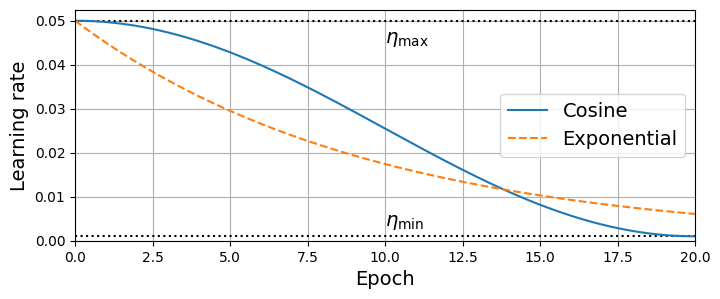

In [65]:
t = np.linspace(0, 20, 400)
eta_min = 0.001
eta_max = 0.05
t2 = 20
eta_cos_t = eta_min + 0.5 * (eta_max - eta_min) * (1 + np.cos(t / t2 * np.pi))
eta_exp_t = 0.9 ** t * eta_max

plt.figure(figsize=(8, 3))
plt.hlines([eta_min, eta_max], 0, 20, color="k", linestyle="dotted")
plt.plot(t, eta_cos_t, label="Cosine")
plt.plot(t, eta_exp_t, "--", label="Exponential")
plt.legend(loc="center right")
plt.text(10, eta_min + 0.0025, r"$\eta_\text{min}$")
plt.text(10, eta_max - 0.005, r"$\eta_\text{max}$")
plt.axis([0, 20, 0, eta_max * 1.05])
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.show()

In [66]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=20, eta_min=0.001)

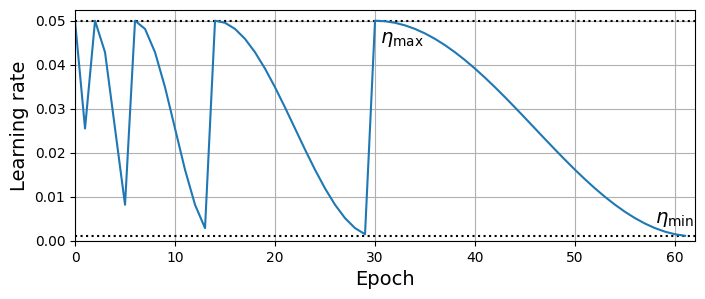

In [67]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
cosine_repeat_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=2, T_mult=2, eta_min=0.001)

lrs = []
for epoch in range(62):
    lrs.append(cosine_repeat_scheduler.get_last_lr()[0])
    cosine_repeat_scheduler.step()

plt.figure(figsize=(8, 3))
plt.hlines([eta_min, eta_max], 0, 64, color="k", linestyle="dotted")
plt.plot(lrs, label="Cosine")
plt.text(30.5, eta_max - 0.005, r"$\eta_\text{max}$")
plt.text(58, eta_min + 0.003, r"$\eta_\text{min}$")
plt.axis([0, 62, 0, eta_max * 1.05])
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.show()

In [68]:
import re

DOCS_URL = "https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler"
for name in sorted(dir(torch.optim.lr_scheduler)):
    scheduler = getattr(torch.optim.lr_scheduler, name)
    if (not name.startswith("_") and isinstance(scheduler, type) and
        issubclass(scheduler, torch.optim.lr_scheduler.LRScheduler)):
            print(f"• {DOCS_URL}.{name}.html")

• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ChainedScheduler.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ConstantLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingWarmRestarts.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CyclicLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ExponentialLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LRScheduler.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LinearLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiStepLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiplicativeLR.html
• https://pytorch.org/docs/sta

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 230kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.25MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.6MB/s]


Epoch 01/62 | Loss: 1.3090 | Test accuracy: 0.7023 | LR: 0.05000
Epoch 02/62 | Loss: 0.7058 | Test accuracy: 0.7583 | LR: 0.02550
Epoch 03/62 | Loss: 0.6394 | Test accuracy: 0.7865 | LR: 0.05000
Epoch 04/62 | Loss: 0.5527 | Test accuracy: 0.8037 | LR: 0.04282
Epoch 05/62 | Loss: 0.5051 | Test accuracy: 0.8126 | LR: 0.02550
Epoch 06/62 | Loss: 0.4879 | Test accuracy: 0.8135 | LR: 0.00818
Epoch 07/62 | Loss: 0.5107 | Test accuracy: 0.8116 | LR: 0.05000
Epoch 08/62 | Loss: 0.4785 | Test accuracy: 0.8047 | LR: 0.04814
Epoch 09/62 | Loss: 0.4574 | Test accuracy: 0.8163 | LR: 0.04282
Epoch 10/62 | Loss: 0.4400 | Test accuracy: 0.8295 | LR: 0.03488
Epoch 11/62 | Loss: 0.4276 | Test accuracy: 0.8347 | LR: 0.02550
Epoch 12/62 | Loss: 0.4197 | Test accuracy: 0.8382 | LR: 0.01612
Epoch 13/62 | Loss: 0.4147 | Test accuracy: 0.8383 | LR: 0.00818
Epoch 14/62 | Loss: 0.4119 | Test accuracy: 0.8399 | LR: 0.00286
Epoch 15/62 | Loss: 0.4407 | Test accuracy: 0.8349 | LR: 0.05000
Epoch 16/62 | Loss: 0.421

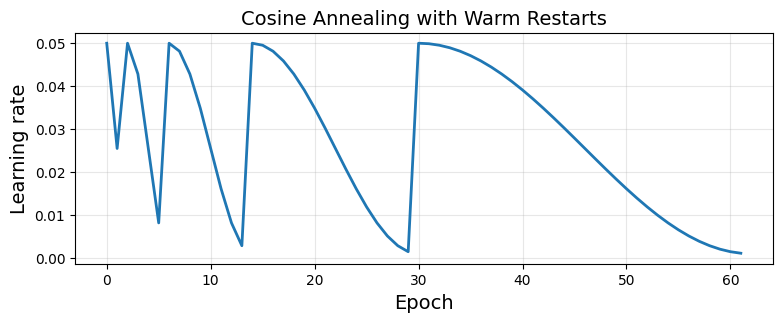

In [69]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Device and dataset
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

train_set = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_set = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_set, batch_size=256, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256)

# 2. Build the model
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 10)
).to(device)

# 3. Optimizer and cosine annealing with warm restarts
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
loss_fn = nn.CrossEntropyLoss()

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=2,
    T_mult=2,
    eta_min=0.001
)

# 4. Train for 62 epochs
n_epochs = 62
history = {"train_loss": [], "test_accuracy": [], "lr": []}

for epoch in range(n_epochs):
    model.train()
    total_loss = 0.0

    # Record the LR used during this epoch
    history["lr"].append(optimizer.param_groups[0]["lr"])

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    train_loss = total_loss / len(train_loader.dataset)
    history["train_loss"].append(train_loss)

    # Evaluate accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            predictions = model(X_batch)
            correct += (predictions.argmax(dim=1) == y_batch).sum().item()
            total += y_batch.size(0)

    accuracy = correct / total
    history["test_accuracy"].append(accuracy)

    print(
        f"Epoch {epoch+1:02d}/{n_epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Test accuracy: {accuracy:.4f} | "
        f"LR: {history['lr'][-1]:.5f}"
    )

    # Update the scheduler AFTER optimizer steps
    scheduler.step()

# 5. Plot the learning-rate schedule
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(range(n_epochs), history["lr"], linewidth=2)
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.set_title("Cosine Annealing with Warm Restarts")
ax.grid(alpha=0.3)
plt.show()

In [70]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, weight_decay=1e-4)
history = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 0.5504, train metric: 0.8002, valid metric: 0.8454
Epoch 2/10, train loss: 0.3959, train metric: 0.8550, valid metric: 0.8700
Epoch 3/10, train loss: 0.3579, train metric: 0.8676, valid metric: 0.8756
Epoch 4/10, train loss: 0.3329, train metric: 0.8773, valid metric: 0.8754
Epoch 5/10, train loss: 0.3164, train metric: 0.8817, valid metric: 0.8816
Epoch 6/10, train loss: 0.3024, train metric: 0.8869, valid metric: 0.8904
Epoch 7/10, train loss: 0.2901, train metric: 0.8913, valid metric: 0.8926
Epoch 8/10, train loss: 0.2798, train metric: 0.8954, valid metric: 0.8982
Epoch 9/10, train loss: 0.2707, train metric: 0.8974, valid metric: 0.9034
Epoch 10/10, train loss: 0.2603, train metric: 0.9024, valid metric: 0.9046


In [71]:
n_epochs = 3
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
loss_fn = nn.CrossEntropyLoss()

model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
params_to_regularize = [
    param for name, param in model.named_parameters()
    if not "bias" in name and not "bn" in name]
for epoch in range(n_epochs):
    total_loss = 0.0
    total_l2_loss = 0.0
    for X_batch, y_batch in train_loader:
        model.train()
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        main_loss = loss_fn(y_pred, y_batch)
        l2_loss = sum(param.pow(2.0).sum() for param in params_to_regularize)
        loss = main_loss + 1e-4 * l2_loss
        total_loss += loss.item()
        total_l2_loss += l2_loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    print(f"Epoch {epoch + 1}/{n_epochs}"
          f" – l2 loss: {total_l2_loss / len(train_loader):.3f}"
          f" – loss: {total_loss / len(train_loader):.3f}")

Epoch 1/3 – l2 loss: 635.867 – loss: 0.615
Epoch 2/3 – l2 loss: 644.383 – loss: 0.462
Epoch 3/3 – l2 loss: 645.678 – loss: 0.423


In [72]:
n_epochs = 3
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
loss_fn = nn.CrossEntropyLoss()

model = build_model()  # extra code
params_to_regularize = [
    param for name, param in model.named_parameters()
    if not "bias" in name and not "bn" in name]
params_bias_and_bn = [
    param for name, param in model.named_parameters()
    if "bias" in name or "bn" in name]
optimizer = torch.optim.SGD([
    {"params": params_to_regularize, "weight_decay": 1e-4},
    {"params": params_bias_and_bn, "weight_decay": 0},
    ], lr=0.05)
for epoch in range(n_epochs):
    total_loss = 0.0
    for X_batch, y_batch in train_loader:
        model.train()
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    print(f"Epoch {epoch + 1}/{n_epochs}"
          f" – loss: {total_loss / len(train_loader):.3f}")

Epoch 1/3 – loss: 0.550
Epoch 2/3 – loss: 0.397
Epoch 3/3 – loss: 0.356


In [73]:
n_epochs = 3
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
loss_fn = nn.CrossEntropyLoss()

model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
params_to_regularize = [
    param for name, param in model.named_parameters()
    if not "bias" in name and not "bn" in name]
for epoch in range(n_epochs):
    total_loss = 0.0
    total_l1_loss = 0.0
    for X_batch, y_batch in train_loader:
        model.train()
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        main_loss = loss_fn(y_pred, y_batch)
        l1_loss = sum(param.abs().sum() for param in params_to_regularize)
        loss = main_loss + 1e-4 * l1_loss
        total_loss += loss.item()
        total_l1_loss += l1_loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    print(f"Epoch {epoch + 1}/{n_epochs}"
          f" – l1 loss: {total_l1_loss / len(train_loader):.3f}"
          f" – loss: {total_loss / len(train_loader):.3f}")

Epoch 1/3 – l1 loss: 5687.238 – loss: 1.122
Epoch 2/3 – l1 loss: 5028.135 – loss: 0.906
Epoch 3/3 – l1 loss: 4437.434 – loss: 0.813


In [74]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(p=0.2), nn.Linear(28 * 28, 100), nn.ReLU(),
    nn.Dropout(p=0.2), nn.Linear(100, 100), nn.ReLU(),
    nn.Dropout(p=0.2), nn.Linear(100, 10)
).to(device)
model.apply(use_he_init)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
history_dropout, acc_dropout = test_optimizer(model, optimizer, batch_size=32)

Epoch 1/10, train loss: 0.6706, train metric: 0.7555, valid metric: 0.8408
Epoch 2/10, train loss: 0.5087, train metric: 0.8150, valid metric: 0.8504
Epoch 3/10, train loss: 0.4705, train metric: 0.8291, valid metric: 0.8500
Epoch 4/10, train loss: 0.4496, train metric: 0.8357, valid metric: 0.8534
Epoch 5/10, train loss: 0.4336, train metric: 0.8422, valid metric: 0.8712
Epoch 6/10, train loss: 0.4214, train metric: 0.8458, valid metric: 0.8736
Epoch 7/10, train loss: 0.4143, train metric: 0.8478, valid metric: 0.8688
Epoch 8/10, train loss: 0.4030, train metric: 0.8532, valid metric: 0.8792
Epoch 9/10, train loss: 0.3986, train metric: 0.8523, valid metric: 0.8766
Epoch 10/10, train loss: 0.3927, train metric: 0.8544, valid metric: 0.8792


In [75]:
torch.manual_seed(42)

model_nodropout = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 100), nn.ReLU(),
    nn.Linear(100, 100), nn.ReLU(),
    nn.Linear(100, 10)
).to(device)

model_nodropout.apply(use_he_init)

optimizer_nodropout = torch.optim.SGD(
    model_nodropout.parameters(),
    lr=0.01,
    momentum=0.9
)

history_nodropout, acc_nodropout = test_optimizer(
    model_nodropout,
    optimizer_nodropout,
    batch_size=32
)

print(f"Accuracy with dropout:    {acc_dropout.item():.2%}")
print(f"Accuracy without dropout: {acc_nodropout.item():.2%}")

Epoch 1/10, train loss: 0.5239, train metric: 0.8124, valid metric: 0.8582
Epoch 2/10, train loss: 0.3862, train metric: 0.8588, valid metric: 0.8744
Epoch 3/10, train loss: 0.3498, train metric: 0.8713, valid metric: 0.8770
Epoch 4/10, train loss: 0.3273, train metric: 0.8789, valid metric: 0.8856
Epoch 5/10, train loss: 0.3099, train metric: 0.8856, valid metric: 0.8900
Epoch 6/10, train loss: 0.2972, train metric: 0.8878, valid metric: 0.8886
Epoch 7/10, train loss: 0.2854, train metric: 0.8924, valid metric: 0.8880
Epoch 8/10, train loss: 0.2762, train metric: 0.8962, valid metric: 0.8986
Epoch 9/10, train loss: 0.2671, train metric: 0.8986, valid metric: 0.8984
Epoch 10/10, train loss: 0.2566, train metric: 0.9038, valid metric: 0.8940
Accuracy with dropout:    86.24%
Accuracy without dropout: 87.49%


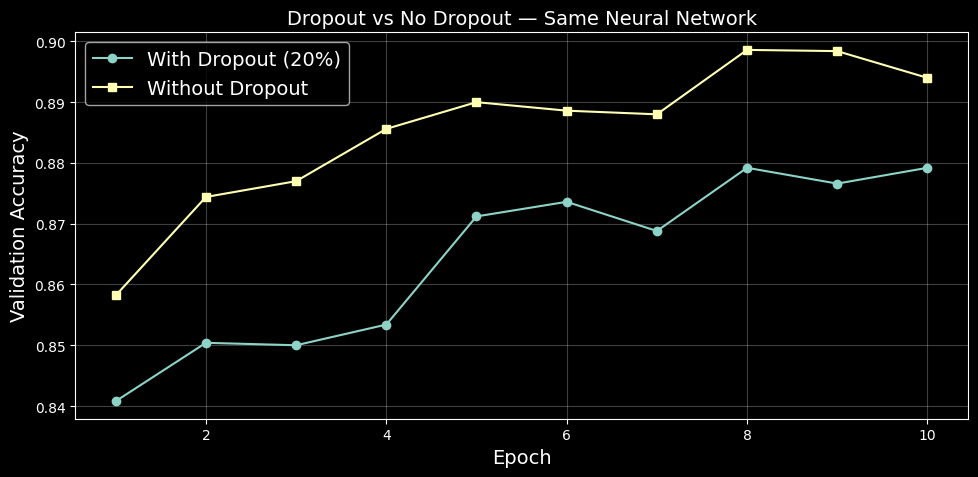

FINAL TEST ACCURACY
With dropout:    86.24%
Without dropout: 87.49%
Difference: -1.25%


In [76]:
import matplotlib.pyplot as plt

# Validation accuracy across epochs
dropout_acc = history_dropout["valid_metrics"]
nodropout_acc = history_nodropout["valid_metrics"]

epochs = range(1, len(dropout_acc) + 1)

plt.style.use("dark_background")
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    dropout_acc,
    marker="o",
    label="With Dropout (20%)"
)

plt.plot(
    epochs,
    nodropout_acc,
    marker="s",
    label="Without Dropout"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Dropout vs No Dropout — Same Neural Network")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Final test accuracy comparison
print("FINAL TEST ACCURACY")
print(f"With dropout:    {acc_dropout.item():.2%}")
print(f"Without dropout: {acc_nodropout.item():.2%}")
print(f"Difference: {(acc_dropout.item() - acc_nodropout.item()):+.2%}")

In [77]:
import torch
import torch.nn as nn
import numpy as np

seeds = [42, 123, 456]
dropout_rates = [0.10, 0.05]

results = {}

for p in dropout_rates:
    results[p] = {
        "histories": [],
        "test_accuracies": []
    }

    for seed in seeds:
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        # Same architecture as your original network
        model_p = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=p),
            nn.Linear(28 * 28, 100),
            nn.ReLU(),

            nn.Dropout(p=p),
            nn.Linear(100, 100),
            nn.ReLU(),

            nn.Dropout(p=p),
            nn.Linear(100, 10)
        ).to(device)

        # Same initialization
        model_p.apply(use_he_init)

        # Same optimizer
        optimizer_p = torch.optim.SGD(
            model_p.parameters(),
            lr=0.01,
            momentum=0.9
        )

        print(f"\nTraining dropout={p}, seed={seed}")

        history_p, accuracy_p = test_optimizer(
            model_p,
            optimizer_p,
            batch_size=32
        )

        results[p]["histories"].append(history_p)
        results[p]["test_accuracies"].append(
            float(accuracy_p.item())
        )

    scores = results[p]["test_accuracies"]

    print(
        f"\nDropout {p:.0%}: "
        f"Mean test accuracy = {np.mean(scores):.2%}, "
        f"SD = {np.std(scores):.2%}"
    )


Training dropout=0.1, seed=42
Epoch 1/10, train loss: 0.5944, train metric: 0.7861, valid metric: 0.8492
Epoch 2/10, train loss: 0.4478, train metric: 0.8376, valid metric: 0.8640
Epoch 3/10, train loss: 0.4141, train metric: 0.8482, valid metric: 0.8582
Epoch 4/10, train loss: 0.3912, train metric: 0.8567, valid metric: 0.8682
Epoch 5/10, train loss: 0.3755, train metric: 0.8625, valid metric: 0.8774
Epoch 6/10, train loss: 0.3618, train metric: 0.8656, valid metric: 0.8792
Epoch 7/10, train loss: 0.3537, train metric: 0.8688, valid metric: 0.8776
Epoch 8/10, train loss: 0.3445, train metric: 0.8727, valid metric: 0.8874
Epoch 9/10, train loss: 0.3402, train metric: 0.8718, valid metric: 0.8866
Epoch 10/10, train loss: 0.3336, train metric: 0.8754, valid metric: 0.8906

Training dropout=0.1, seed=123
Epoch 1/10, train loss: 0.5919, train metric: 0.7883, valid metric: 0.8454
Epoch 2/10, train loss: 0.4486, train metric: 0.8355, valid metric: 0.8626
Epoch 3/10, train loss: 0.4141, trai

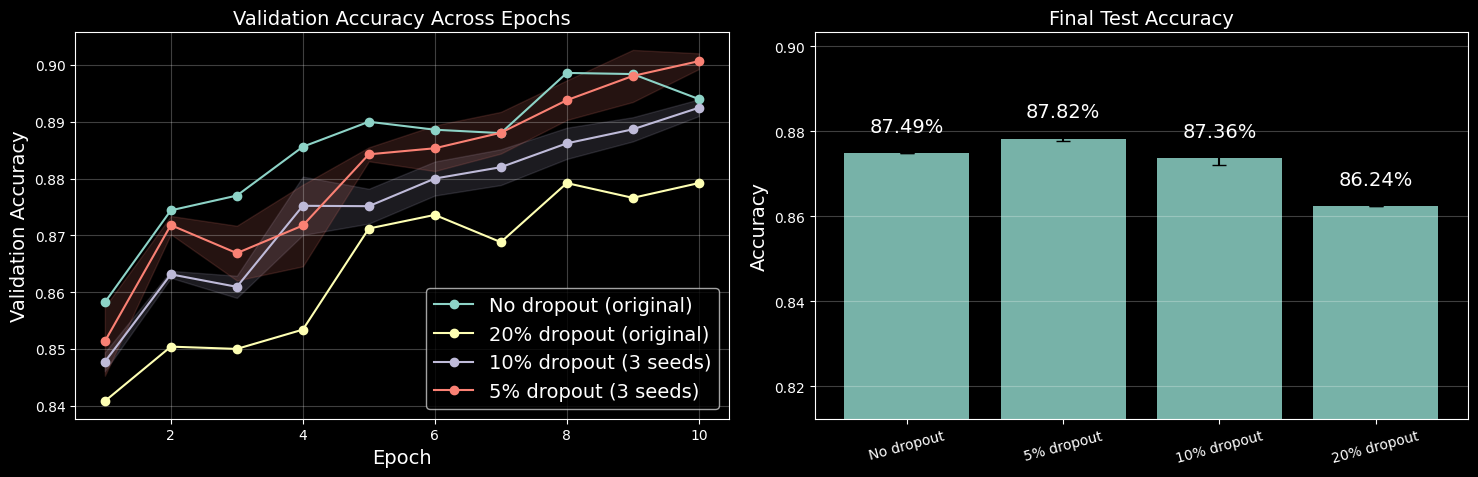

In [78]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("dark_background")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Original models: one run each
old_results = {
    "No dropout (original)": (
        np.array(history_nodropout["valid_metrics"]),
        float(acc_nodropout.item())
    ),
    "20% dropout (original)": (
        np.array(history_dropout["valid_metrics"]),
        float(acc_dropout.item())
    )
}

# LEFT: Validation accuracy across epochs
for label, (values, _) in old_results.items():
    axes[0].plot(
        range(1, len(values) + 1),
        values,
        marker="o",
        label=label
    )

# New dropout models: mean across seeds
for p in dropout_rates:
    curves = np.array([
        h["valid_metrics"]
        for h in results[p]["histories"]
    ])

    mean_curve = curves.mean(axis=0)
    std_curve = curves.std(axis=0)

    epochs = np.arange(1, len(mean_curve) + 1)

    line, = axes[0].plot(
        epochs,
        mean_curve,
        marker="o",
        label=f"{p:.0%} dropout (3 seeds)"
    )

    axes[0].fill_between(
        epochs,
        mean_curve - std_curve,
        mean_curve + std_curve,
        color=line.get_color(),
        alpha=0.15
    )

axes[0].set_title("Validation Accuracy Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

# RIGHT: Final test accuracy
labels = [
    "No dropout",
    "5% dropout",
    "10% dropout",
    "20% dropout"
]

test_means = [
    float(acc_nodropout.item()),
    np.mean(results[0.05]["test_accuracies"]),
    np.mean(results[0.10]["test_accuracies"]),
    float(acc_dropout.item())
]

test_stds = [
    0,
    np.std(results[0.05]["test_accuracies"]),
    np.std(results[0.10]["test_accuracies"]),
    0
]

bars = axes[1].bar(
    labels,
    test_means,
    yerr=test_stds,
    capsize=5,
    alpha=0.85
)

for bar, value in zip(bars, test_means):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.005,
        f"{value:.2%}",
        ha="center"
    )

axes[1].set_ylim(
    min(test_means) - 0.05,
    max(test_means) + 0.025
)
axes[1].set_title("Final Test Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [79]:
model.eval()
for module in model.modules():
    if isinstance(module, nn.Dropout):
        module.train()

X_new = torch.FloatTensor(fashion_mnist.data[:3].reshape(3, 1, 28, 28) / 255)
X_new = X_new.to(device)

torch.manual_seed(42)
with torch.no_grad():
    X_new_repeated = X_new.repeat_interleave(100, dim=0)
    y_logits_all = model(X_new_repeated).reshape(3, 100, 10)
    y_probas_all = torch.nn.functional.softmax(y_logits_all, dim=-1)
    y_probas = y_probas_all.mean(dim=1)

In [80]:
y_probas.round(decimals=2)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000,
         0.9900],
        [0.9900, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000, 0.0000,
         0.0000],
        [0.4900, 0.0400, 0.0300, 0.2200, 0.0300, 0.0000, 0.1800, 0.0000, 0.0000,
         0.0000]])

In [81]:
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Dropout(p=0.2, inplace=False)
  (2): Linear(in_features=784, out_features=100, bias=True)
  (3): ReLU()
  (4): Dropout(p=0.2, inplace=False)
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Dropout(p=0.2, inplace=False)
  (8): Linear(in_features=100, out_features=10, bias=True)
)


In [82]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. Use your previously trained 20% dropout model
# This is the model trained in your original dropout experiment
mc_model = model_dropout if "model_dropout" in globals() else None

# If that model wasn't saved, train it again
if mc_model is None:
    torch.manual_seed(42)

    mc_model = nn.Sequential(
        nn.Flatten(),
        nn.Dropout(p=0.2),
        nn.Linear(784, 100),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(100, 10)
    ).to(device)

    mc_model.apply(use_he_init)

    optimizer_mc = torch.optim.SGD(
        mc_model.parameters(),
        lr=0.01,
        momentum=0.9
    )

    history_mc, acc_mc = test_optimizer(
        mc_model, optimizer_mc, batch_size=32
    )

# 2. Keep evaluation mode but reactivate dropout
mc_model.eval()

for module in mc_model.modules():
    if isinstance(module, nn.Dropout):
        module.train()

# 3. Prepare three Fashion-MNIST images
X_new = (
    fashion_mnist.data[:3]
    .reshape(3, 1, 28, 28)
    .float() / 255
).to(device)

# 4. Run 100 Monte Carlo predictions per image
torch.manual_seed(42)

with torch.no_grad():
    X_repeated = X_new.repeat_interleave(100, dim=0)

    logits = mc_model(X_repeated).reshape(3, 100, 10)

    probabilities = F.softmax(logits, dim=-1)

    y_probas = probabilities.mean(dim=1)

    uncertainty = probabilities.std(dim=1)

# 5. Show results
print("Dropout probabilities:",
      [m.p for m in mc_model.modules()
       if isinstance(m, nn.Dropout)])

print("\nAverage predicted probabilities:")
print(y_probas.round(decimals=2))

print("\nPredicted clothing classes:")
print(y_probas.argmax(dim=1))

print("\nStandard deviation across 100 predictions:")
print(uncertainty.round(decimals=3))

Epoch 1/10, train loss: 0.6706, train metric: 0.7555, valid metric: 0.8408
Epoch 2/10, train loss: 0.5087, train metric: 0.8150, valid metric: 0.8504
Epoch 3/10, train loss: 0.4705, train metric: 0.8291, valid metric: 0.8500
Epoch 4/10, train loss: 0.4496, train metric: 0.8357, valid metric: 0.8534
Epoch 5/10, train loss: 0.4336, train metric: 0.8422, valid metric: 0.8712
Epoch 6/10, train loss: 0.4214, train metric: 0.8458, valid metric: 0.8736
Epoch 7/10, train loss: 0.4143, train metric: 0.8478, valid metric: 0.8688
Epoch 8/10, train loss: 0.4030, train metric: 0.8532, valid metric: 0.8792
Epoch 9/10, train loss: 0.3986, train metric: 0.8523, valid metric: 0.8766
Epoch 10/10, train loss: 0.3927, train metric: 0.8544, valid metric: 0.8792


AttributeError: 'numpy.ndarray' object has no attribute 'float'

In [83]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. Keep your trained model and enable dropout
mc_model.eval()

for module in mc_model.modules():
    if isinstance(module, nn.Dropout):
        module.train()

# 2. Fix NumPy-to-PyTorch conversion
X_new = torch.as_tensor(
    fashion_mnist.data[:3].reshape(3, 1, 28, 28),
    dtype=torch.float32,
    device=device
) / 255.0

# 3. Run 100 dropout experiments per image
torch.manual_seed(42)

with torch.no_grad():
    X_repeated = X_new.repeat_interleave(100, dim=0)

    logits = mc_model(X_repeated).reshape(3, 100, 10)

    probabilities = F.softmax(logits, dim=-1)

    y_probas = probabilities.mean(dim=1)
    uncertainty = probabilities.std(dim=1)

# 4. Display results
print("Dropout rates:",
      [m.p for m in mc_model.modules()
       if isinstance(m, nn.Dropout)])

print("\nAverage class probabilities:")
print(y_probas.round(decimals=2))

print("\nPredicted classes:")
print(y_probas.argmax(dim=1))

print("\nPrediction variability:")
print(uncertainty.round(decimals=3))

Dropout rates: [0.2, 0.2, 0.2]

Average class probabilities:
tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000,
         0.9900],
        [0.9900, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000, 0.0000,
         0.0000],
        [0.4900, 0.0400, 0.0300, 0.2200, 0.0300, 0.0000, 0.1800, 0.0000, 0.0000,
         0.0000]])

Predicted classes:
tensor([9, 0, 0])

Prediction variability:
tensor([[0.0010, 0.0000, 0.0020, 0.0000, 0.0010, 0.0180, 0.0000, 0.0290, 0.0000,
         0.0340],
        [0.0220, 0.0000, 0.0000, 0.0020, 0.0000, 0.0000, 0.0200, 0.0000, 0.0000,
         0.0000],
        [0.2040, 0.0460, 0.0350, 0.1370, 0.0530, 0.0010, 0.0720, 0.0020, 0.0030,
         0.0010]])


In [84]:
class McDropout(nn.Dropout):
    def forward(self, input):
        return F.dropout(input, self.p, training=True)

In [85]:
def mean_prediction(model, X, n_repeats):
    X_new_repeated = X_new.repeat_interleave(n_repeats, dim=0)
    y_logits = model(X_new_repeated)
    y_logits_all = y_logits.reshape(X.shape[0], n_repeats, *y_logits.shape[1:])
    y_probas_all = torch.nn.functional.softmax(y_logits_all, dim=-1)
    return y_probas_all.mean(dim=1)

In [86]:
with torch.no_grad():
  y_mean_pred = mean_prediction(model, X_new, 100)

y_mean_pred.round(decimals=2)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000,
         0.9900],
        [0.9900, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000, 0.0000,
         0.0000],
        [0.5400, 0.0300, 0.0300, 0.1900, 0.0300, 0.0000, 0.1800, 0.0000, 0.0000,
         0.0000]])

In [87]:
def apply_max_norm(model, max_norm=2, epsilon=1e-8, dim=1):
    with torch.no_grad():
        for name, param in model.named_parameters():
            if 'bias' not in name:
                actual_norm = param.norm(p=2, dim=dim, keepdim=True)
                target_norm = torch.clamp(actual_norm, 0, max_norm)
                param *= target_norm / (epsilon + actual_norm)

In [89]:
torch.manual_seed(42)

n_epochs = 3
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
loss_fn = nn.CrossEntropyLoss()

model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
for epoch in range(n_epochs):
    total_loss = 0.0
    for X_batch, y_batch in train_loader:
        model.train()
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        apply_max_norm(model)
    print(f"Epoch {epoch + 1}/{n_epochs}"
          f" – loss: {total_loss / len(train_loader):.3f}")

Epoch 1/3 – loss: 0.549
Epoch 2/3 – loss: 0.396
Epoch 3/3 – loss: 0.356


Ex #8

In [92]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import CIFAR10
from torchvision.transforms import v2 as T

transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
])

train_and_valid_set = CIFAR10(
    root="datasets", train=True, download=True, transform=transform
)
test_set = CIFAR10(
    root="datasets", train=False, download=True, transform=transform
)

train_set, valid_set = random_split(
    train_and_valid_set,
    [45_000, 5_000],
    generator=torch.Generator().manual_seed(42),
)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

images, labels = next(iter(train_loader))
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)

100%|██████████| 170M/170M [00:21<00:00, 8.12MB/s]


Images: torch.Size([128, 3, 32, 32]) torch.float32
Labels: torch.Size([128]) torch.int64


In [93]:
import torch
from torch import nn

layers = [nn.Flatten(start_dim=1)]
in_features = 3 * 32 * 32

for _ in range(20):
    hidden = nn.Linear(in_features, 100)
    nn.init.kaiming_normal_(hidden.weight, mode="fan_in", nonlinearity="relu")
    nn.init.zeros_(hidden.bias)

    layers.extend([hidden, nn.SiLU()])
    in_features = 100

layers.append(nn.Linear(in_features, 10))
model = nn.Sequential(*layers)

with torch.no_grad():
    logits = model(images)

print("Logits shape:", logits.shape)  # Expected: torch.Size([128, 10])

Logits shape: torch.Size([128, 10])


In [94]:
from copy import deepcopy

import torch
from torch import nn
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loss_fn = nn.CrossEntropyLoss()

initial_model = deepcopy(model).cpu()
learning_rates = [1e-4, 3e-4, 1e-3, 3e-3]
short_epochs = 1
extra_epochs = 2
max_epochs = 30
patience = 5


def evaluate(network, loader):
    network.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = network(images)
            total_loss += loss_fn(logits, labels).item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += labels.size(0)

    return total_loss / total_examples, total_correct / total_examples


def run_epoch(trial):
    network = trial["model"]
    optimizer = trial["optimizer"]
    network.train()
    total_loss = 0.0
    total_examples = 0

    for images, labels in trial["train_loader"]:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = loss_fn(network(images), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_examples += labels.size(0)

    val_loss, val_accuracy = evaluate(network, valid_loader)
    epoch = len(trial["history"]) + 1
    trial["history"].append({
        "epoch": epoch,
        "train_loss": total_loss / total_examples,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    })

    if val_loss < trial["best_loss"]:
        trial["best_loss"] = val_loss
        trial["best_epoch"] = epoch
        trial["best_weights"] = deepcopy(network.state_dict())

    print(
        f"lr={trial['lr']:g} | epoch={epoch:02d} | "
        f"val loss={val_loss:.4f} | val accuracy={val_accuracy:.2%}"
    )


def latest_val_loss(trial):
    return trial["history"][-1]["val_loss"]


trials = []
for lr in learning_rates:
    candidate = deepcopy(initial_model).to(device)
    trial = {
        "lr": lr,
        "model": candidate,
        "optimizer": torch.optim.NAdam(candidate.parameters(), lr=lr),
        "train_loader": DataLoader(
            train_set,
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(42),
        ),
        "history": [],
        "best_loss": float("inf"),
        "best_epoch": 0,
        "best_weights": None,
    }
    for _ in range(short_epochs):
        run_epoch(trial)
    trials.append(trial)

finalists = sorted(trials, key=latest_val_loss)[:2]
for trial in finalists:
    for _ in range(extra_epochs):
        run_epoch(trial)

winner = min(finalists, key=latest_val_loss)

while len(winner["history"]) < max_epochs:
    run_epoch(winner)
    if len(winner["history"]) - winner["best_epoch"] >= patience:
        break

model = winner["model"]
model.load_state_dict(winner["best_weights"])
model.eval()
baseline_history = winner["history"]

print(
    f"Selected lr={winner['lr']:g}. Restored epoch {winner['best_epoch']} "
    f"with validation loss {winner['best_loss']:.4f}."
)

lr=0.0001 | epoch=01 | val loss=1.9261 | val accuracy=28.70%
lr=0.0003 | epoch=01 | val loss=1.9178 | val accuracy=29.18%
lr=0.001 | epoch=01 | val loss=2.0471 | val accuracy=20.56%
lr=0.003 | epoch=01 | val loss=2.0561 | val accuracy=18.88%
lr=0.0003 | epoch=02 | val loss=1.8764 | val accuracy=31.70%
lr=0.0003 | epoch=03 | val loss=1.7020 | val accuracy=37.92%
lr=0.0001 | epoch=02 | val loss=1.8176 | val accuracy=33.40%
lr=0.0001 | epoch=03 | val loss=1.7082 | val accuracy=38.72%
lr=0.0003 | epoch=04 | val loss=1.6935 | val accuracy=38.60%
lr=0.0003 | epoch=05 | val loss=1.6331 | val accuracy=41.22%
lr=0.0003 | epoch=06 | val loss=1.6120 | val accuracy=42.84%
lr=0.0003 | epoch=07 | val loss=1.5337 | val accuracy=44.96%
lr=0.0003 | epoch=08 | val loss=1.5036 | val accuracy=45.36%
lr=0.0003 | epoch=09 | val loss=1.5254 | val accuracy=45.20%
lr=0.0003 | epoch=10 | val loss=1.5047 | val accuracy=46.30%
lr=0.0003 | epoch=11 | val loss=1.4936 | val accuracy=47.44%
lr=0.0003 | epoch=12 | val

Batch-norm learning-rate search
lr=0.0001 | epoch=01 | val loss=2.2407 | val accuracy=16.38%
lr=0.0003 | epoch=01 | val loss=1.9650 | val accuracy=28.00%
lr=0.001 | epoch=01 | val loss=1.7416 | val accuracy=36.46%
lr=0.003 | epoch=01 | val loss=1.9801 | val accuracy=31.74%
lr=0.001 | epoch=02 | val loss=1.6271 | val accuracy=42.02%
lr=0.001 | epoch=03 | val loss=1.5568 | val accuracy=44.98%
lr=0.0003 | epoch=02 | val loss=1.7497 | val accuracy=36.86%
lr=0.0003 | epoch=03 | val loss=1.6391 | val accuracy=41.22%

Baseline at lr=0.0003
lr=0.0003 | epoch=01 | val loss=1.9178 | val accuracy=29.18%
lr=0.0003 | epoch=02 | val loss=1.8764 | val accuracy=31.70%
lr=0.0003 | epoch=03 | val loss=1.7020 | val accuracy=37.92%
lr=0.0003 | epoch=04 | val loss=1.6935 | val accuracy=38.60%
lr=0.0003 | epoch=05 | val loss=1.6331 | val accuracy=41.22%
lr=0.0003 | epoch=06 | val loss=1.6120 | val accuracy=42.84%
lr=0.0003 | epoch=07 | val loss=1.5337 | val accuracy=44.96%
lr=0.0003 | epoch=08 | val loss=1.

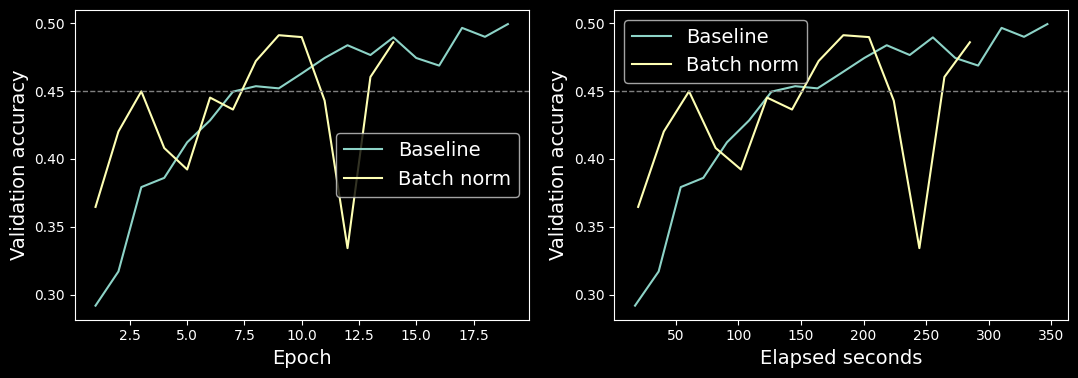

In [96]:
from time import perf_counter

import matplotlib.pyplot as plt

# initial_model is the untrained snapshot from Exercise 8.3.
bn_layers = []
for layer in initial_model:
    if isinstance(layer, nn.SiLU):
        bn_layers.append(nn.BatchNorm1d(bn_layers[-1].out_features))
    bn_layers.append(deepcopy(layer))

bn_initial_model = nn.Sequential(*bn_layers)


def make_trial(template, lr):
    network = deepcopy(template).to(device)
    return {
        "lr": lr,
        "model": network,
        "optimizer": torch.optim.NAdam(network.parameters(), lr=lr),
        "train_loader": DataLoader(
            train_set,
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(42),
        ),
        "history": [],
        "best_loss": float("inf"),
        "best_epoch": 0,
        "best_weights": None,
    }


# Use the same two-round search as in Exercise 8.3.
print("Batch-norm learning-rate search")
bn_trials = []
for lr in learning_rates:
    trial = make_trial(bn_initial_model, lr)
    for _ in range(short_epochs):
        run_epoch(trial)
    bn_trials.append(trial)

bn_finalists = sorted(bn_trials, key=latest_val_loss)[:2]
for trial in bn_finalists:
    for _ in range(extra_epochs):
        run_epoch(trial)

bn_lr = min(bn_finalists, key=latest_val_loss)["lr"]
baseline_lr = winner["lr"]


def timed_run(name, template, lr):
    print(f"\n{name} at lr={lr:g}")
    trial = make_trial(template, lr)

    if device.type == "cuda":
        torch.cuda.synchronize()
    started = perf_counter()

    for _ in range(max_epochs):
        run_epoch(trial)
        if device.type == "cuda":
            torch.cuda.synchronize()

        row = trial["history"][-1]
        row["seconds"] = perf_counter() - started

        if row["epoch"] - trial["best_epoch"] >= patience:
            break

    trial["model"].load_state_dict(trial["best_weights"])
    trial["model"].eval()
    return trial


baseline_run = timed_run("Baseline", initial_model, baseline_lr)
bn_run = timed_run("Batch norm", bn_initial_model, bn_lr)
bn_model = bn_run["model"]

# 45% is a comparison target based on your baseline run.
target_accuracy = 0.45
fig, (by_epoch, by_time) = plt.subplots(1, 2, figsize=(11, 4))

for name, trial in [("Baseline", baseline_run), ("Batch norm", bn_run)]:
    history = trial["history"]
    accuracies = [row["val_accuracy"] for row in history]
    by_epoch.plot([row["epoch"] for row in history], accuracies, label=name)
    by_time.plot([row["seconds"] for row in history], accuracies, label=name)

    first_hit = next(
        (row for row in history if row["val_accuracy"] >= target_accuracy),
        None,
    )
    best = history[trial["best_epoch"] - 1]
    average_seconds = history[-1]["seconds"] / len(history)
    print(
        f"\n{name} | mean seconds/epoch: {average_seconds:.1f} | "
        f"peak accuracy: {max(accuracies):.2%} | "
        f"restored epoch {best['epoch']}: "
        f"loss {best['val_loss']:.4f}, accuracy {best['val_accuracy']:.2%}"
    )
    if first_hit is None:
        print(f"  {target_accuracy:.0%} validation accuracy was never reached.")
    else:
        print(
            f"  First reached {target_accuracy:.0%} at epoch "
            f"{first_hit['epoch']} after {first_hit['seconds']:.1f} seconds."
        )

for axis, xlabel in [(by_epoch, "Epoch"), (by_time, "Elapsed seconds")]:
    axis.axhline(target_accuracy, color="gray", linestyle="--", linewidth=1)
    axis.set(xlabel=xlabel, ylabel="Validation accuracy")
    axis.legend()

fig.tight_layout()
plt.show()

In [97]:
import math

# Accumulate statistics from the training split only.
n_features = 3 * 32 * 32
feature_sum = torch.zeros(n_features, dtype=torch.float64)
feature_sum_sq = torch.zeros_like(feature_sum)
n_images = 0

stats_loader = DataLoader(train_set, batch_size=batch_size, shuffle=False)
for images_batch, _ in stats_loader:
    features = images_batch.flatten(start_dim=1).to(torch.float64)
    feature_sum += features.sum(dim=0)
    feature_sum_sq += features.square().sum(dim=0)
    n_images += features.size(0)

pixel_mean = feature_sum / n_images
pixel_variance = feature_sum_sq / n_images - pixel_mean.square()
pixel_std = pixel_variance.clamp_min(0).sqrt()
pixel_std[pixel_std == 0] = 1


class StandardizeFeatures(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", mean.float())
        self.register_buffer("std", std.float())

    def forward(self, features):
        return (features - self.mean) / self.std


# Reuse the original linear dimensions and replace the hidden activations.
selu_layers = [
    nn.Flatten(start_dim=1),
    StandardizeFeatures(pixel_mean, pixel_std),
]
for layer in initial_model:
    if isinstance(layer, nn.Linear) and layer.out_features == 100:
        hidden = deepcopy(layer)
        nn.init.normal_(hidden.weight, mean=0.0, std=1 / math.sqrt(hidden.in_features))
        nn.init.zeros_(hidden.bias)
        selu_layers.extend([hidden, nn.SELU()])

selu_layers.append(deepcopy(initial_model[-1]))
selu_initial_model = nn.Sequential(*selu_layers)

print("SELU learning-rate search")
selu_trials = []
for lr in learning_rates:
    trial = make_trial(selu_initial_model, lr)
    for _ in range(short_epochs):
        run_epoch(trial)
    selu_trials.append(trial)

selu_finalists = sorted(selu_trials, key=latest_val_loss)[:2]
for trial in selu_finalists:
    for _ in range(extra_epochs):
        run_epoch(trial)

selu_lr = min(selu_finalists, key=latest_val_loss)["lr"]
selu_run = timed_run("SELU", selu_initial_model, selu_lr)
selu_model = selu_run["model"]

history = selu_run["history"]
best = history[selu_run["best_epoch"] - 1]
print(
    f"\nSELU | mean seconds/epoch: {history[-1]['seconds'] / len(history):.1f} | "
    f"peak accuracy: {max(row['val_accuracy'] for row in history):.2%} | "
    f"restored epoch {best['epoch']}: "
    f"loss {best['val_loss']:.4f}, accuracy {best['val_accuracy']:.2%}"
)

first_hit = next(
    (row for row in history if row["val_accuracy"] >= target_accuracy),
    None,
)
if first_hit is None:
    print(f"SELU never reached {target_accuracy:.0%} validation accuracy.")
else:
    print(
        f"SELU first reached {target_accuracy:.0%} at epoch "
        f"{first_hit['epoch']} after {first_hit['seconds']:.1f} seconds."
    )

SELU learning-rate search
lr=0.0001 | epoch=01 | val loss=1.7090 | val accuracy=38.32%
lr=0.0003 | epoch=01 | val loss=1.6718 | val accuracy=40.78%
lr=0.001 | epoch=01 | val loss=1.7496 | val accuracy=37.84%
lr=0.003 | epoch=01 | val loss=1.9584 | val accuracy=26.62%
lr=0.0003 | epoch=02 | val loss=1.5828 | val accuracy=44.00%
lr=0.0003 | epoch=03 | val loss=1.5194 | val accuracy=46.14%
lr=0.0001 | epoch=02 | val loss=1.6009 | val accuracy=43.64%
lr=0.0001 | epoch=03 | val loss=1.5547 | val accuracy=44.76%

SELU at lr=0.0003
lr=0.0003 | epoch=01 | val loss=1.6718 | val accuracy=40.78%
lr=0.0003 | epoch=02 | val loss=1.5828 | val accuracy=44.00%
lr=0.0003 | epoch=03 | val loss=1.5194 | val accuracy=46.14%
lr=0.0003 | epoch=04 | val loss=1.5432 | val accuracy=45.44%
lr=0.0003 | epoch=05 | val loss=1.4989 | val accuracy=47.82%
lr=0.0003 | epoch=06 | val loss=1.4685 | val accuracy=48.62%
lr=0.0003 | epoch=07 | val loss=1.4738 | val accuracy=49.48%
lr=0.0003 | epoch=08 | val loss=1.4400 | v

In [98]:
dropout_rate = 0.1
mc_passes = 30

# Insert alpha dropout between the last hidden SELU and the classifier.
alpha_layers = [deepcopy(layer) for layer in selu_initial_model]
alpha_layers.insert(len(alpha_layers) - 1, nn.AlphaDropout(p=dropout_rate))
alpha_initial_model = nn.Sequential(*alpha_layers)

print("Alpha dropout learning-rate search")
alpha_trials = []
for lr in learning_rates:
    trial = make_trial(alpha_initial_model, lr)
    for _ in range(short_epochs):
        run_epoch(trial)
    alpha_trials.append(trial)

alpha_finalists = sorted(alpha_trials, key=latest_val_loss)[:2]
for trial in alpha_finalists:
    for _ in range(extra_epochs):
        run_epoch(trial)

alpha_lr = min(alpha_finalists, key=latest_val_loss)["lr"]
alpha_run = timed_run("SELU with alpha dropout", alpha_initial_model, alpha_lr)
alpha_model = alpha_run["model"]

ordinary_loss, ordinary_accuracy = evaluate(alpha_model, valid_loader)


@torch.inference_mode()
def mc_dropout_accuracy(network, loader, passes):
    network.eval()
    for layer in network.modules():
        if isinstance(layer, nn.AlphaDropout):
            layer.train()

    total_correct = 0
    total_examples = 0

    try:
        for images_batch, labels in loader:
            images_batch = images_batch.to(device)
            labels = labels.to(device)

            probability_sum = network(images_batch).softmax(dim=1)
            for _ in range(passes - 1):
                probability_sum += network(images_batch).softmax(dim=1)

            mean_probabilities = probability_sum / passes
            predictions = mean_probabilities.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_examples += labels.size(0)
    finally:
        network.eval()

    return total_correct / total_examples


mc_accuracy = mc_dropout_accuracy(alpha_model, valid_loader, mc_passes)
selu_accuracy = selu_run["history"][selu_run["best_epoch"] - 1]["val_accuracy"]

print(f"\nSELU without dropout:      {selu_accuracy:.2%}")
print(f"Alpha dropout, ordinary:   {ordinary_accuracy:.2%}")
print(f"Alpha dropout, MC ({mc_passes} passes): {mc_accuracy:.2%}")
print(f"MC gain: {100 * (mc_accuracy - ordinary_accuracy):+.2f} percentage points")

Alpha dropout learning-rate search
lr=0.0001 | epoch=01 | val loss=1.7115 | val accuracy=39.58%
lr=0.0003 | epoch=01 | val loss=1.6763 | val accuracy=41.54%
lr=0.001 | epoch=01 | val loss=1.7857 | val accuracy=36.10%
lr=0.003 | epoch=01 | val loss=2.0781 | val accuracy=21.96%
lr=0.0003 | epoch=02 | val loss=1.5696 | val accuracy=45.84%
lr=0.0003 | epoch=03 | val loss=1.5428 | val accuracy=46.74%
lr=0.0001 | epoch=02 | val loss=1.6350 | val accuracy=43.14%
lr=0.0001 | epoch=03 | val loss=1.5737 | val accuracy=46.04%

SELU with alpha dropout at lr=0.0003
lr=0.0003 | epoch=01 | val loss=1.6782 | val accuracy=40.02%
lr=0.0003 | epoch=02 | val loss=1.5854 | val accuracy=45.18%
lr=0.0003 | epoch=03 | val loss=1.5194 | val accuracy=47.16%
lr=0.0003 | epoch=04 | val loss=1.5800 | val accuracy=46.24%
lr=0.0003 | epoch=05 | val loss=1.4968 | val accuracy=48.54%
lr=0.0003 | epoch=06 | val loss=1.5020 | val accuracy=49.52%
lr=0.0003 | epoch=07 | val loss=1.5740 | val accuracy=48.92%
lr=0.0003 | ep

In [99]:
from time import perf_counter

comparison_epochs = 10
peak_rates = [3e-4, 1e-3, 3e-3]


def train_for_comparison(name, lr, use_one_cycle=False):
    torch.manual_seed(42)
    trial = make_trial(alpha_initial_model, lr)
    network = trial["model"]
    optimizer = trial["optimizer"]
    loader = trial["train_loader"]

    scheduler = None
    if use_one_cycle:
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=lr,
            epochs=comparison_epochs,
            steps_per_epoch=len(loader),
            pct_start=0.3,
            cycle_momentum=False,
        )

    if device.type == "cuda":
        torch.cuda.synchronize()
    started = perf_counter()

    for epoch in range(1, comparison_epochs + 1):
        network.train()

        for images_batch, labels in loader:
            images_batch = images_batch.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = loss_fn(network(images_batch), labels)
            loss.backward()
            optimizer.step()

            if scheduler is not None:
                scheduler.step()

        val_loss, val_accuracy = evaluate(network, valid_loader)
        if val_loss < trial["best_loss"]:
            trial["best_loss"] = val_loss
            trial["best_epoch"] = epoch
            trial["best_weights"] = deepcopy(network.state_dict())

        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = perf_counter() - started

        trial["history"].append({
            "epoch": epoch,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "seconds": elapsed,
        })
        print(
            f"{name} | epoch {epoch:02d} | "
            f"val loss {val_loss:.4f} | val accuracy {val_accuracy:.2%}"
        )

    network.load_state_dict(trial["best_weights"])
    network.eval()
    return trial


fixed_run = train_for_comparison("Fixed rate", alpha_lr)

cycle_runs = [
    train_for_comparison(f"One-cycle peak {peak:g}", peak, use_one_cycle=True)
    for peak in peak_rates
]
cycle_run = min(cycle_runs, key=lambda trial: trial["best_loss"])
cycle_model = cycle_run["model"]

print(f"\nSelected one-cycle peak rate: {cycle_run['lr']:g}")

for name, trial in [("Fixed rate", fixed_run), ("One-cycle", cycle_run)]:
    history = trial["history"]
    best = history[trial["best_epoch"] - 1]
    first_hit = next(
        (row for row in history if row["val_accuracy"] >= target_accuracy),
        None,
    )

    print(
        f"\n{name} | total time: {history[-1]['seconds']:.1f} s | "
        f"restored epoch {best['epoch']} | "
        f"val loss {best['val_loss']:.4f} | "
        f"val accuracy {best['val_accuracy']:.2%}"
    )
    if first_hit is None:
        print(f"  Never reached {target_accuracy:.0%} validation accuracy.")
    else:
        print(
            f"  Reached {target_accuracy:.0%} at epoch {first_hit['epoch']} "
            f"after {first_hit['seconds']:.1f} s."
        )

Fixed rate | epoch 01 | val loss 1.6904 | val accuracy 41.30%
Fixed rate | epoch 02 | val loss 1.6087 | val accuracy 44.30%
Fixed rate | epoch 03 | val loss 1.5656 | val accuracy 46.78%
Fixed rate | epoch 04 | val loss 1.5492 | val accuracy 46.56%
Fixed rate | epoch 05 | val loss 1.5315 | val accuracy 48.10%
Fixed rate | epoch 06 | val loss 1.5002 | val accuracy 49.74%
Fixed rate | epoch 07 | val loss 1.5291 | val accuracy 49.62%
Fixed rate | epoch 08 | val loss 1.4893 | val accuracy 50.82%
Fixed rate | epoch 09 | val loss 1.5457 | val accuracy 49.32%
Fixed rate | epoch 10 | val loss 1.5450 | val accuracy 49.42%
One-cycle peak 0.0003 | epoch 01 | val loss 1.8037 | val accuracy 35.06%
One-cycle peak 0.0003 | epoch 02 | val loss 1.7025 | val accuracy 40.02%
One-cycle peak 0.0003 | epoch 03 | val loss 1.6048 | val accuracy 44.86%
One-cycle peak 0.0003 | epoch 04 | val loss 1.5764 | val accuracy 45.86%
One-cycle peak 0.0003 | epoch 05 | val loss 1.5194 | val accuracy 47.04%
One-cycle peak 

In [100]:
from time import perf_counter

epochs = 20
peak_lr = 1e-3

torch.manual_seed(42)
long_trial = make_trial(alpha_initial_model, peak_lr)
network = long_trial["model"]
optimizer = long_trial["optimizer"]
loader = long_trial["train_loader"]

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=peak_lr,
    epochs=epochs,
    steps_per_epoch=len(loader),
    pct_start=0.3,
    cycle_momentum=False,
)

long_cycle_history = []
best_row = None
best_weights = None
started = perf_counter()

for epoch in range(1, epochs + 1):
    network.train()
    train_correct = torch.zeros((), dtype=torch.long, device=device)
    train_examples = 0

    for images_batch, labels in loader:
        images_batch = images_batch.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = network(images_batch)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        train_correct += (logits.detach().argmax(dim=1) == labels).sum()
        train_examples += labels.size(0)

    train_accuracy = train_correct.item() / train_examples
    val_loss, val_accuracy = evaluate(network, valid_loader)
    row = {
        "epoch": epoch,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
        "seconds": perf_counter() - started,
    }
    long_cycle_history.append(row)

    # Select by validation accuracy, with validation loss as the tiebreaker.
    if best_row is None or (val_accuracy, -val_loss) > (
        best_row["val_accuracy"], -best_row["val_loss"]
    ):
        best_row = row
        best_weights = deepcopy(network.state_dict())

    print(
        f"Epoch {epoch:02d} | train accuracy {train_accuracy:.2%} | "
        f"val accuracy {val_accuracy:.2%} | val loss {val_loss:.4f}"
    )

network.load_state_dict(best_weights)
long_cycle_model = network.eval()

reference_accuracy = max(row["val_accuracy"] for row in cycle_run["history"])
gain = 100 * (best_row["val_accuracy"] - reference_accuracy)

print(f"\n10-epoch reference: {reference_accuracy:.2%}")
print(
    f"20-epoch run: {best_row['val_accuracy']:.2%} at epoch "
    f"{best_row['epoch']} ({gain:+.2f} percentage points)"
)
print(f"Total time: {long_cycle_history[-1]['seconds']:.1f} s")

Epoch 01 | train accuracy 30.20% | val accuracy 37.88% | val loss 1.7498
Epoch 02 | train accuracy 39.47% | val accuracy 41.06% | val loss 1.6829
Epoch 03 | train accuracy 43.22% | val accuracy 42.54% | val loss 1.6223
Epoch 04 | train accuracy 45.53% | val accuracy 41.38% | val loss 1.7209
Epoch 05 | train accuracy 47.00% | val accuracy 44.38% | val loss 1.5997
Epoch 06 | train accuracy 48.95% | val accuracy 45.48% | val loss 1.6637
Epoch 07 | train accuracy 50.70% | val accuracy 45.94% | val loss 1.5964
Epoch 08 | train accuracy 52.54% | val accuracy 49.72% | val loss 1.4764
Epoch 09 | train accuracy 54.86% | val accuracy 48.36% | val loss 1.5561
Epoch 10 | train accuracy 56.49% | val accuracy 50.10% | val loss 1.4987
Epoch 11 | train accuracy 58.54% | val accuracy 50.34% | val loss 1.5115
Epoch 12 | train accuracy 60.69% | val accuracy 51.28% | val loss 1.4750
Epoch 13 | train accuracy 63.30% | val accuracy 50.90% | val loss 1.5756
Epoch 14 | train accuracy 65.70% | val accuracy 51.

In [101]:
from time import perf_counter

dropout_template = deepcopy(alpha_initial_model)
for layer in dropout_template.modules():
    if isinstance(layer, nn.AlphaDropout):
        layer.p = 0.20

torch.manual_seed(42)
dropout_trial = make_trial(dropout_template, lr=1e-3)
network = dropout_trial["model"]
optimizer = dropout_trial["optimizer"]
loader = dropout_trial["train_loader"]

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=1e-3,
    epochs=10,
    steps_per_epoch=len(loader),
    pct_start=0.3,
    cycle_momentum=False,
)

dropout_history = []
best_row = None
best_weights = None
started = perf_counter()

for epoch in range(1, 11):
    network.train()

    for images_batch, labels in loader:
        images_batch = images_batch.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        loss = loss_fn(network(images_batch), labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

    val_loss, val_accuracy = evaluate(network, valid_loader)
    row = {
        "epoch": epoch,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
    }
    dropout_history.append(row)

    score = (val_accuracy, -val_loss)
    if best_row is None or score > (
        best_row["val_accuracy"], -best_row["val_loss"]
    ):
        best_row = row
        best_weights = deepcopy(network.state_dict())

    print(
        f"Epoch {epoch:02d} | val accuracy {val_accuracy:.2%} | "
        f"val loss {val_loss:.4f}"
    )

network.load_state_dict(best_weights)
strong_dropout_model = network.eval()

reference = max(row["val_accuracy"] for row in cycle_run["history"])
gain = 100 * (best_row["val_accuracy"] - reference)
print(f"\nAlpha dropout 0.10: {reference:.2%}")
print(
    f"Alpha dropout 0.20: {best_row['val_accuracy']:.2%} "
    f"at epoch {best_row['epoch']} ({gain:+.2f} percentage points)"
)
print(f"Elapsed time: {perf_counter() - started:.1f} s")

Epoch 01 | val accuracy 37.50% | val loss 1.8265
Epoch 02 | val accuracy 40.94% | val loss 1.7386
Epoch 03 | val accuracy 42.18% | val loss 1.7327
Epoch 04 | val accuracy 42.48% | val loss 1.7287
Epoch 05 | val accuracy 47.38% | val loss 1.6018
Epoch 06 | val accuracy 48.76% | val loss 1.5927
Epoch 07 | val accuracy 50.30% | val loss 1.5834
Epoch 08 | val accuracy 52.46% | val loss 1.5503
Epoch 09 | val accuracy 52.78% | val loss 1.5912
Epoch 10 | val accuracy 53.14% | val loss 1.6205

Alpha dropout 0.10: 53.76%
Alpha dropout 0.20: 53.14% at epoch 10 (-0.62 percentage points)
Elapsed time: 196.1 s


In [102]:
from time import perf_counter

width = 200
epochs = 10
peak_lr = 1e-3

torch.manual_seed(42)
layers = [
    nn.Flatten(start_dim=1),
    StandardizeFeatures(pixel_mean, pixel_std),
]

in_features = 3 * 32 * 32
for _ in range(20):
    hidden = nn.Linear(in_features, width)
    nn.init.normal_(hidden.weight, std=in_features ** -0.5)
    nn.init.zeros_(hidden.bias)
    layers.extend([hidden, nn.SELU()])
    in_features = width

layers.extend([nn.AlphaDropout(p=0.10), nn.Linear(width, 10)])
wide_template = nn.Sequential(*layers)

torch.manual_seed(42)
wide_trial = make_trial(wide_template, lr=peak_lr)
wide_model = wide_trial["model"]
optimizer = wide_trial["optimizer"]
loader = wide_trial["train_loader"]

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=peak_lr,
    epochs=epochs,
    steps_per_epoch=len(loader),
    pct_start=0.3,
    cycle_momentum=False,
)

wide_history = []
best_row = None
best_weights = None
started = perf_counter()

for epoch in range(1, epochs + 1):
    wide_model.train()
    train_correct = torch.zeros((), dtype=torch.long, device=device)
    train_examples = 0

    for images_batch, labels in loader:
        images_batch = images_batch.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = wide_model(images_batch)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        train_correct += (logits.detach().argmax(dim=1) == labels).sum()
        train_examples += labels.size(0)

    train_accuracy = train_correct.item() / train_examples
    val_loss, val_accuracy = evaluate(wide_model, valid_loader)
    row = {
        "epoch": epoch,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
    }
    wide_history.append(row)

    if best_row is None or (val_accuracy, -val_loss) > (
        best_row["val_accuracy"], -best_row["val_loss"]
    ):
        best_row = row
        best_weights = deepcopy(wide_model.state_dict())

    print(
        f"Epoch {epoch:02d} | train accuracy {train_accuracy:.2%} | "
        f"val accuracy {val_accuracy:.2%} | val loss {val_loss:.4f}"
    )

elapsed = perf_counter() - started
wide_model.load_state_dict(best_weights)
wide_model.eval()

reference = max(cycle_run["history"], key=lambda row: row["val_accuracy"])
reference_time = cycle_run["history"][-1]["seconds"]
gain = 100 * (best_row["val_accuracy"] - reference["val_accuracy"])

print(f"\nWidth 100: {reference['val_accuracy']:.2%} | {reference_time:.1f} s")
print(
    f"Width 200: {best_row['val_accuracy']:.2%} at epoch {best_row['epoch']} "
    f"({gain:+.2f} percentage points) | {elapsed:.1f} s"
)
print(f"Runtime ratio: {elapsed / reference_time:.2f}×")

Epoch 01 | train accuracy 34.10% | val accuracy 38.80% | val loss 1.7737
Epoch 02 | train accuracy 40.18% | val accuracy 39.78% | val loss 1.7335
Epoch 03 | train accuracy 43.34% | val accuracy 42.78% | val loss 1.7050
Epoch 04 | train accuracy 46.22% | val accuracy 44.24% | val loss 1.7021
Epoch 05 | train accuracy 49.88% | val accuracy 46.26% | val loss 1.5462
Epoch 06 | train accuracy 53.35% | val accuracy 50.64% | val loss 1.5267
Epoch 07 | train accuracy 57.70% | val accuracy 51.64% | val loss 1.4620
Epoch 08 | train accuracy 62.66% | val accuracy 53.92% | val loss 1.4396
Epoch 09 | train accuracy 67.63% | val accuracy 53.98% | val loss 1.4958
Epoch 10 | train accuracy 71.34% | val accuracy 54.00% | val loss 1.5485

Width 100: 53.76% | 190.4 s
Width 200: 54.00% at epoch 10 (+0.24 percentage points) | 263.1 s
Runtime ratio: 1.38×


In [103]:
from time import perf_counter

hidden_layers = 5
epochs = 10
peak_lr = 1e-3

# The template starts with Flatten and StandardizeFeatures.
# Each hidden block then contributes one Linear and one SELU.
original_layers = list(alpha_initial_model.children())
through_last_hidden = 2 + 2 * hidden_layers

shallow_template = nn.Sequential(
    *(
        deepcopy(layer)
        for layer in original_layers[:through_last_hidden] + original_layers[-2:]
    )
)

torch.manual_seed(42)
shallow_trial = make_trial(shallow_template, lr=peak_lr)
shallow_model = shallow_trial["model"]
optimizer = shallow_trial["optimizer"]
loader = shallow_trial["train_loader"]

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=peak_lr,
    epochs=epochs,
    steps_per_epoch=len(loader),
    pct_start=0.3,
    cycle_momentum=False,
)

shallow_history = []
best_score = (-float("inf"), -float("inf"))
best_weights = None
started = perf_counter()

for epoch in range(1, epochs + 1):
    shallow_model.train()
    train_correct = torch.zeros((), dtype=torch.long, device=device)
    train_examples = 0

    for images_batch, labels in loader:
        images_batch, labels = images_batch.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = shallow_model(images_batch)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        train_correct += (logits.detach().argmax(dim=1) == labels).sum()
        train_examples += labels.size(0)

    train_accuracy = train_correct.item() / train_examples
    val_loss, val_accuracy = evaluate(shallow_model, valid_loader)
    shallow_history.append({
        "epoch": epoch,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
    })

    score = (val_accuracy, -val_loss)
    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_weights = deepcopy(shallow_model.state_dict())

    print(
        f"Epoch {epoch:02d} | train accuracy {train_accuracy:.2%} | "
        f"val accuracy {val_accuracy:.2%} | val loss {val_loss:.4f}"
    )

elapsed = perf_counter() - started
shallow_model.load_state_dict(best_weights)
shallow_model.eval()

reference_accuracy = max(row["val_accuracy"] for row in cycle_run["history"])
reference_time = cycle_run["history"][-1]["seconds"]
gain = 100 * (best_score[0] - reference_accuracy)

print(f"\n20 layers: {reference_accuracy:.2%} | {reference_time:.1f} s")
print(
    f" 5 layers: {best_score[0]:.2%} at epoch {best_epoch} "
    f"({gain:+.2f} percentage points) | {elapsed:.1f} s"
)

Epoch 01 | train accuracy 31.81% | val accuracy 42.72% | val loss 1.6406
Epoch 02 | train accuracy 42.91% | val accuracy 45.10% | val loss 1.5701
Epoch 03 | train accuracy 47.70% | val accuracy 48.10% | val loss 1.4798
Epoch 04 | train accuracy 51.18% | val accuracy 48.18% | val loss 1.5161
Epoch 05 | train accuracy 54.65% | val accuracy 49.36% | val loss 1.4427
Epoch 06 | train accuracy 57.87% | val accuracy 51.92% | val loss 1.4373
Epoch 07 | train accuracy 60.95% | val accuracy 52.34% | val loss 1.4365
Epoch 08 | train accuracy 64.24% | val accuracy 53.04% | val loss 1.4375
Epoch 09 | train accuracy 67.14% | val accuracy 53.12% | val loss 1.4616
Epoch 10 | train accuracy 68.85% | val accuracy 52.90% | val loss 1.4638

20 layers: 53.76% | 190.4 s
 5 layers: 53.12% at epoch 9 (-0.64 percentage points) | 162.9 s


In [104]:
from time import perf_counter

epochs = 10
peak_lr = 1e-3

torch.manual_seed(42)
flip_generator = torch.Generator().manual_seed(123)

flip_trial = make_trial(alpha_initial_model, lr=peak_lr)
flip_model = flip_trial["model"]
optimizer = flip_trial["optimizer"]
loader = flip_trial["train_loader"]

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=peak_lr,
    epochs=epochs,
    steps_per_epoch=len(loader),
    pct_start=0.3,
    cycle_momentum=False,
)

flip_history = []
best_row = None
best_weights = None
started = perf_counter()

for epoch in range(1, epochs + 1):
    flip_model.train()

    for images_batch, labels in loader:
        # One flip decision per image, shared across channels and pixels.
        flip_mask = torch.rand(images_batch.size(0), generator=flip_generator) < 0.5
        images_batch = torch.where(
            flip_mask[:, None, None, None],
            images_batch.flip(dims=(-1,)),
            images_batch,
        )
        images_batch, labels = images_batch.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = loss_fn(flip_model(images_batch), labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

    val_loss, val_accuracy = evaluate(flip_model, valid_loader)
    row = {"epoch": epoch, "val_accuracy": val_accuracy, "val_loss": val_loss}
    flip_history.append(row)

    if best_row is None or (val_accuracy, -val_loss) > (
        best_row["val_accuracy"], -best_row["val_loss"]
    ):
        best_row = row
        best_weights = deepcopy(flip_model.state_dict())

    print(
        f"Epoch {epoch:02d} | val accuracy {val_accuracy:.2%} | "
        f"val loss {val_loss:.4f}"
    )

elapsed = perf_counter() - started
flip_model.load_state_dict(best_weights)
flip_model.eval()

reference = max(row["val_accuracy"] for row in cycle_run["history"])
gain = 100 * (best_row["val_accuracy"] - reference)

print(f"\nUnaugmented reference: {reference:.2%}")
print(
    f"Random flips: {best_row['val_accuracy']:.2%} at epoch "
    f"{best_row['epoch']} ({gain:+.2f} percentage points) | {elapsed:.1f} s"
)

Epoch 01 | val accuracy 37.74% | val loss 1.7559
Epoch 02 | val accuracy 40.80% | val loss 1.7002
Epoch 03 | val accuracy 42.46% | val loss 1.6343
Epoch 04 | val accuracy 45.52% | val loss 1.6241
Epoch 05 | val accuracy 47.00% | val loss 1.5371
Epoch 06 | val accuracy 50.02% | val loss 1.4985
Epoch 07 | val accuracy 51.02% | val loss 1.4267
Epoch 08 | val accuracy 52.12% | val loss 1.3909
Epoch 09 | val accuracy 53.94% | val loss 1.3765
Epoch 10 | val accuracy 54.10% | val loss 1.3801

Unaugmented reference: 53.76%
Random flips: 54.10% at epoch 10 (+0.34 percentage points) | 195.8 s


In [105]:
import torch
from torch.utils.data import DataLoader
from copy import deepcopy
from time import perf_counter

final_epochs = 10
final_peak_lr = 1e-3
torch.manual_seed(42)

full_train_set = train_and_valid_set

# Refit standardization now that the old validation images are part of training.
stats_loader = DataLoader(full_train_set, batch_size=batch_size, shuffle=False)
feature_sum = torch.zeros(3 * 32 * 32, dtype=torch.float64)
feature_sum_sq = torch.zeros_like(feature_sum)

for images_batch, _ in stats_loader:
    features = images_batch.flatten(start_dim=1).to(torch.float64)
    feature_sum += features.sum(dim=0)
    feature_sum_sq += features.square().sum(dim=0)

full_mean = feature_sum / len(full_train_set)
full_variance = feature_sum_sq / len(full_train_set) - full_mean.square()
full_std = full_variance.clamp_min(0).sqrt()
full_std[full_std == 0] = 1.0

# The template already contains the selected architecture and alpha dropout.
final_model = deepcopy(alpha_initial_model)
final_model[1] = StandardizeFeatures(full_mean, full_std)
final_model = final_model.to(device)

full_train_loader = DataLoader(
    full_train_set,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
flip_generator = torch.Generator().manual_seed(123)

optimizer = torch.optim.NAdam(final_model.parameters(), lr=final_peak_lr)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=final_peak_lr,
    epochs=final_epochs,
    steps_per_epoch=len(full_train_loader),
    pct_start=0.3,
    cycle_momentum=False,
)

started = perf_counter()

for epoch in range(1, final_epochs + 1):
    final_model.train()
    epoch_loss = torch.zeros((), device=device)
    epoch_correct = torch.zeros((), dtype=torch.long, device=device)

    for images_batch, labels in full_train_loader:
        flip_mask = torch.rand(images_batch.size(0), generator=flip_generator) < 0.5
        images_batch = torch.where(
            flip_mask[:, None, None, None],
            images_batch.flip(dims=(-1,)),
            images_batch,
        )
        images_batch, labels = images_batch.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = final_model(images_batch)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        epoch_loss += loss.detach() * labels.size(0)
        epoch_correct += (logits.detach().argmax(dim=1) == labels).sum()

    train_loss = epoch_loss.item() / len(full_train_set)
    train_accuracy = epoch_correct.item() / len(full_train_set)
    print(
        f"Epoch {epoch:02d}/{final_epochs} | "
        f"train loss {train_loss:.4f} | train accuracy {train_accuracy:.2%}"
    )

print(f"\nFull training time: {perf_counter() - started:.1f} s")

# evaluate() uses model.eval() and torch.inference_mode().
test_loss, test_accuracy = evaluate(final_model, test_loader)
print(f"Final test loss:     {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.2%}")

Epoch 01/10 | train loss 1.9043 | train accuracy 31.23%
Epoch 02/10 | train loss 1.6906 | train accuracy 39.96%
Epoch 03/10 | train loss 1.6027 | train accuracy 43.50%
Epoch 04/10 | train loss 1.5261 | train accuracy 46.07%
Epoch 05/10 | train loss 1.4565 | train accuracy 48.74%
Epoch 06/10 | train loss 1.3829 | train accuracy 51.37%
Epoch 07/10 | train loss 1.3099 | train accuracy 53.80%
Epoch 08/10 | train loss 1.2276 | train accuracy 56.57%
Epoch 09/10 | train loss 1.1581 | train accuracy 58.99%
Epoch 10/10 | train loss 1.1098 | train accuracy 60.59%

Full training time: 201.5 s
Final test loss:     1.3726
Final test accuracy: 53.49%


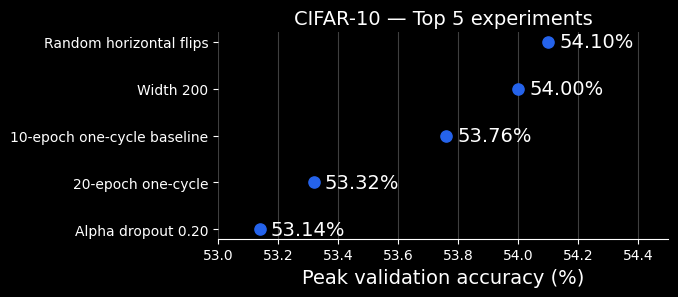

In [106]:
import matplotlib.pyplot as plt

experiments = [
    ("Random horizontal flips", 54.10),
    ("Width 200", 54.00),
    ("10-epoch one-cycle baseline", 53.76),
    ("20-epoch one-cycle", 53.32),
    ("Alpha dropout 0.20", 53.14),
]

names, scores = zip(*experiments)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(scores, names, color="#2563eb", s=65, zorder=3)
ax.invert_yaxis()

for name, score in experiments:
    ax.annotate(
        f"{score:.2f}%",
        (score, name),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
    )

ax.set_title("CIFAR-10 — Top 5 experiments")
ax.set_xlabel("Peak validation accuracy (%)")
ax.set_xlim(53.0, 54.5)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)

fig.tight_layout()
plt.show()